<h1>Creación de Modelos Predictivos</h1>
<p>
En la actualidad, las organizaciones generan grandes volúmenes de datos sobre el comportamiento de sus clientes y sobre las condiciones en que opera su negocio. La minería de datos permite convertir esa información en conocimiento útil, y los modelos predictivos son una de sus herramientas centrales, ya que estiman eventos futuros a partir de patrones observados en datos históricos. Dentro de la Inteligencia de Negocios, estos modelos apoyan decisiones como a qué clientes dirigir una campaña, cuánto inventario preparar o cómo asignar recursos de forma más eficiente.
Esta práctica aplica esos conceptos a dos problemas reales de la UCI Machine Learning Repository.
<br><br>
El primero es un problema de clasificación sobre el conjunto Online Shoppers Purchasing Intention, cuyo objetivo es predecir si una sesión de navegación en una tienda en línea terminará en una compra (Revenue) a partir del comportamiento del usuario, las métricas de las páginas visitadas y el contexto de la visita. El segundo es un problema de regresión sobre el conjunto Seoul Bike Sharing Demand, que busca estimar el número de bicicletas alquiladas por hora considerando las condiciones meteorológicas y temporales.
<br><br>
Para el problema de clasificación se construyen y comparan dos algoritmos, Naive Bayes y Árbol de Decisión. Se evalúan mediante exactitud, precisión, recall y F1-score, con el cálculo manual de las métricas a partir de las matrices de confusión y una validación cruzada estratificada de cinco folds. Para el problema de regresión se desarrollan una Regresión Lineal Múltiple y un Árbol de Decisión para Regresión, con una partición cronológica de los datos y la evaluación con MAE, RMSE y R². En ambos casos se aplican las etapas del proceso de minería de datos: exploración de los datos, preparación y transformación de variables (escalado estándar de las numéricas y codificación dummy de las categóricas), modelado y evaluación.
<br><br>
El objetivo no es solo obtener modelos con buen desempeño, sino interpretar sus resultados desde la perspectiva de la Inteligencia de Negocios. Para ello se analizan las consecuencias que tienen los distintos tipos de error en cada contexto, se justifica la selección del modelo más adecuado y se reflexiona sobre la utilidad práctica de las predicciones y sus limitaciones.     
</p>

<h2>Importar las Librerías Necesarias</h2>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

<h2>Funciones de Utilidades Generales</h2>

<b>Nombre:</b> descripcion_estadistica_numerica <br>
<b>Argumentos:</b> <br>
    <b>(DataFrame) df:</b> Representa el dataframe que contiene los datos. <br>
    <b>(String) columna:</b> Representa la columna numérica que se va a utilizar para obtener las medidas. <br>
<b>Objetivo: </b> Mostrar los valores estadísticos más importantes de una columna númerica (media, mínimo, máximo, rango, desviación estándar). <br>
<b>Retorno: </b>-

In [2]:
def descripcion_estadistica_numerica(df,columna):
    print("Media de",columna,":",df[columna].mean())
    print("Valor Mínimo de",columna,":",df[columna].min())
    print("Valor Máximo de",columna,":",df[columna].max())
    print("Rango de Valores en",columna,"(maximo - minimo):",df[columna].max() - df[columna].min())
    print("Desviación Estándar en",columna,df[columna].std())

<h2>1. Modelos de Clasificación</h2>
<hr>
<p>Los modelos de clasificación son una de las técnicas más utilizadas en la minería de datos. Su propósito es asignar cada observación a una categoría a partir de sus características, aprendiendo de datos históricos cuyo resultado ya se conoce. En esta sección se desarrolla un problema de clasificación binaria con el conjunto de datos Online Shoppers Purchasing Intention, que reúne sesiones de navegación de una tienda en línea.
</p>

In [3]:
df_clasificacion = pd.read_csv("online_shoppers_intention.csv")

<h3>1.1 Exploración de la Fuente de Datos</h3>
<p>Antes de iniciar el proceso de preparación es necesario conocer ciertos aspectos de la fuente de datos. En este caso se evaluaron los siguientes aspectos para saber el nivel de calidad de los datos existentes y si es necesario aplicar alguna transformación para realizar correcciones a alguno de los datos.</p>

<b>Inspección Inicial Básica</b>

In [4]:
print("Vista previa de los primeros 5 registros:")
df_clasificacion.head()

Vista previa de los primeros 5 registros:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [5]:
print("Forma de la fuente de datos: (Filas x Columnas)",df_clasificacion.shape)

Forma de la fuente de datos: (Filas x Columnas) (12330, 18)


<b>Consideraciones de Análisis de Calidad de los Datos</b>
<ul>
    <li>Validar la existencia de los valores nulos.</li>
    <li>Validar que los tipos de datos sean consistentes con la información que almacenan.</li>
    <li>Validar que las variables categóricas que almacenan texto no tengan conflictos tipográficos.</li>
</ul>

In [6]:
print("Cantidad de valores vacios en cada columna:")
df_clasificacion.isna().sum()

Cantidad de valores vacios en cada columna:


Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

In [7]:
print("Información de los tipos de datos y valores no nulos:")
df_clasificacion.info()

Información de los tipos de datos y valores no nulos:
<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 no

In [8]:
print("Validación de los valores de las variables categóricas:")
print("Valores de Month: ",df_clasificacion["Month"].unique())
print("Valores de VisitorType: ",df_clasificacion["VisitorType"].unique())

Validación de los valores de las variables categóricas:
Valores de Month:  <ArrowStringArray>
['Feb', 'Mar', 'May', 'Oct', 'June', 'Jul', 'Aug', 'Nov', 'Sep', 'Dec']
Length: 10, dtype: str
Valores de VisitorType:  <ArrowStringArray>
['Returning_Visitor', 'New_Visitor', 'Other']
Length: 3, dtype: str


<b>Consideraciones de la Exploración Estadística</b>
<ul>
    <li>Visualizar la media, valor mínimo, valor máximo y el rango de valores que tienen algunas columnas numéricas importantes.</li>
    <li>Utilizar visualizaciones para conocer algunos patrones que pueden ser de interes.</li>
    <li>Validar la correlación entre las variables numéricas involucradas.</li>
    <li>Validar la distribución de los datos de la variable objetivo para conocer como los datos se distribuiran antes de realizar la estratificación en el modelo.</li>
</ul>

In [9]:
descripcion_estadistica_numerica(df_clasificacion,"ProductRelated_Duration")

Media de ProductRelated_Duration : 1194.7462199688268
Valor Mínimo de ProductRelated_Duration : 0.0
Valor Máximo de ProductRelated_Duration : 63973.52223
Rango de Valores en ProductRelated_Duration (maximo - minimo): 63973.52223
Desviación Estándar en ProductRelated_Duration 1913.6692878720035


In [10]:
descripcion_estadistica_numerica(df_clasificacion,"Administrative")

Media de Administrative : 2.3151662611516626
Valor Mínimo de Administrative : 0
Valor Máximo de Administrative : 27
Rango de Valores en Administrative (maximo - minimo): 27
Desviación Estándar en Administrative 3.3217841061569113


In [11]:
descripcion_estadistica_numerica(df_clasificacion,"ProductRelated")

Media de ProductRelated : 31.731467964314678
Valor Mínimo de ProductRelated : 0
Valor Máximo de ProductRelated : 705
Rango de Valores en ProductRelated (maximo - minimo): 705
Desviación Estándar en ProductRelated 44.47550330493652


In [12]:
descripcion_estadistica_numerica(df_clasificacion,"Informational")

Media de Informational : 0.5035685320356853
Valor Mínimo de Informational : 0
Valor Máximo de Informational : 24
Rango de Valores en Informational (maximo - minimo): 24
Desviación Estándar en Informational 1.270156425983391


In [13]:
print("Distribución de los Valores de Revenue:")
print(df_clasificacion.groupby("Revenue")["Revenue"].count())

Distribución de los Valores de Revenue:
Revenue
False    10422
True      1908
Name: Revenue, dtype: int64


Text(0.5, 1.0, 'Distribución de Revenue según VisitorType')

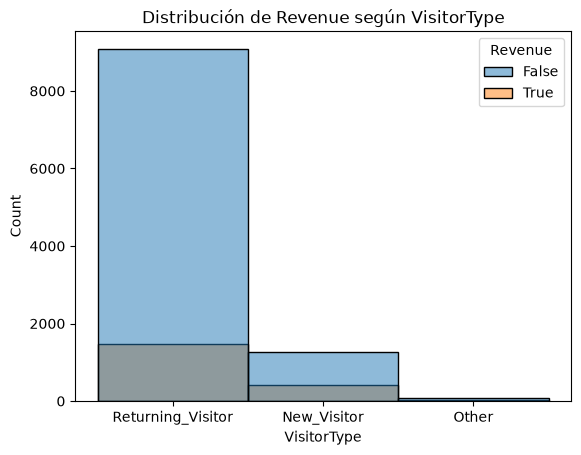

In [14]:
sns.histplot(data=df_clasificacion,x="VisitorType",hue="Revenue",bins=15).set_title("Distribución de Revenue según VisitorType")

Text(0.5, 1.0, 'Distribución de Revenue según Month')

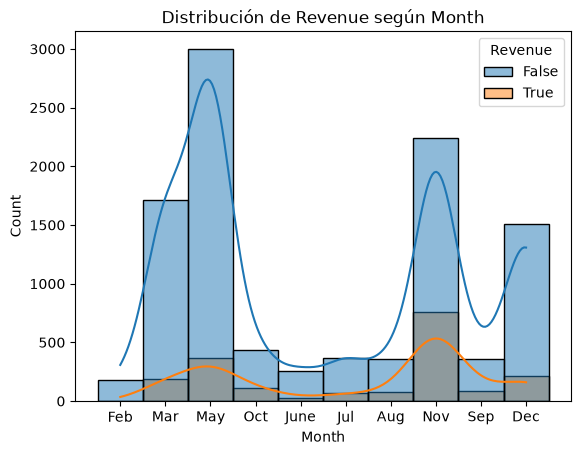

In [15]:
sns.histplot(data=df_clasificacion,x="Month",hue="Revenue",bins=15,kde=True).set_title("Distribución de Revenue según Month")

Text(0.5, 1.0, 'Duración en Páginas de Producto vs Tasa de Salida')

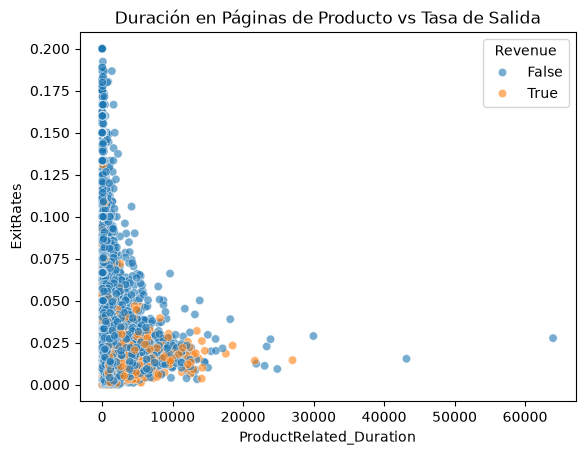

In [16]:
(sns.scatterplot(data=df_clasificacion, x='ProductRelated_Duration', y='ExitRates', hue='Revenue', alpha=0.6)
 .set_title("Duración en Páginas de Producto vs Tasa de Salida"))

Text(0.5, 1.0, 'Correlación entre métricas web')

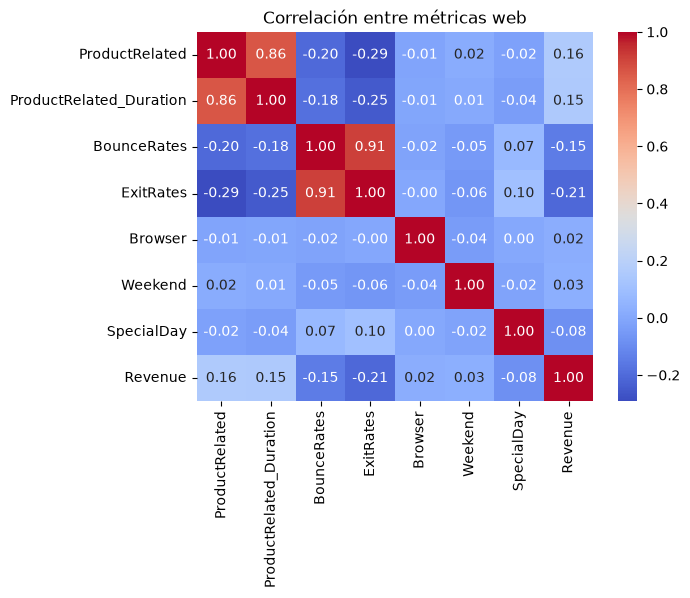

In [17]:
cols_num = ["ProductRelated", "ProductRelated_Duration","BounceRates","ExitRates","Browser","Weekend","SpecialDay","Revenue"]
sns.heatmap(df_clasificacion[cols_num].corr(), annot=True, cmap='coolwarm', fmt=".2f").set_title("Correlación entre métricas web")

<b>Conclusiones de la Exploración de la Fuente de Datos</b>
<p>
El conjunto de datos contiene 12330 sesiones de navegación y 18 variables. La revisión de calidad no encontró valores nulos en ninguna columna, y los tipos de datos son consistentes con la información que almacenan (7 enteros, 7 decimales, 2 booleanos y 2 textos). Las variables categóricas Month y VisitorType no presentan conflictos tipográficos. Month abarca 10 meses del año (no aparecen enero ni abril) y VisitorType tiene tres categorías: Returning_Visitor, New_Visitor y Other. Por lo tanto, no fue necesario aplicar correcciones sobre los datos.
    
En la exploración estadística se observó que la actividad se concentra en las páginas de productos. ProductRelated tiene una media de 31.73 páginas por sesión, con un máximo de 705 y una desviación estándar de 44.48. Esto indica una distribución muy dispersa y sesgada hacia la derecha, con sesiones muy largas que coexisten con otras de muy poca actividad. Las páginas administrativas (media de 2.32) e informativas (media de 0.50) tienen un uso mucho menor, y en ambos casos la desviación estándar supera a la media.

La variable objetivo Revenue está desbalanceada: 10422 sesiones (84.5 %) no terminaron en compra frente a 1908 (15.5 %) que sí lo hicieron. Por esto, al construir los modelos es necesario estratificar la partición entre entrenamiento y prueba, y no basarse únicamente en la exactitud para evaluar su desempeño.

La mayoría de las sesiones corresponden a visitantes recurrentes, que concentran también el mayor número absoluto de compras. Sin embargo, la categoría de nuevos visitantes se encuentra más balanceada, haciendo que una mayor cantidad de los escenarios los nuevos visitantes realicen una sesión que concluya en una compra. La categoría de otros es una categoría marginal por lo tanto no se registran tantas sesiones provenientes de este grupo.

El mayor volumen de sesiones se da en mayo, pero noviembre registra el mayor número de compras y la mayor proporción de conversión, con aproximadamente una compra por cada tres sesiones sin compra. Marzo y diciembre también tienen tráfico alto, mientras que febrero, junio, julio y agosto son meses de baja actividad. El pico de noviembre es consistente con el efecto de eventos comerciales masivos, aunque esa explicación proviene de conocimiento externo y no de los datos.

Las sesiones con compra se concentran en tasas de salida bajas (por debajo de 0.05) y se extienden hacia duraciones más largas. Las tasas de salida altas (por encima de 0.10) corresponden casi exclusivamente a sesiones sin compra con poco tiempo en páginas de producto. Hay una correlación muy alta entre ProductRelated y ProductRelated_Duration (0.86) y entre BounceRates y ExitRates (0.91), por lo que estos pares aportan información redundante. Respecto a Revenue, las relaciones son débiles: positivas con ProductRelated (0.16) y ProductRelated_Duration (0.15), y negativas con ExitRates (-0.21), BounceRates (-0.15) y SpecialDay (-0.08). Browser y Weekend casi no se asocian con la compra.

En conjunto, los datos están limpios y listos para modelar, y la compra se asocia con una mayor interacción con productos, menores tasas de salida y rebote, y con la temporada (en especial noviembre). Ninguna variable numérica por sí sola explica la compra, lo que justifica usar modelos multivariados como Naive Bayes y árboles de decisión. Además, el desbalance de Revenue obliga a evaluar con métricas como precisión, sensibilidad y F1, y no solo con exactitud si se desea tomar una decisión más apropiada cuando se comparen los modelos.
</p>

<h3>1.2 Identificación de las Variables</h3>
<p>
El conjunto de datos para este modelo de clasificación está compuesto por 10 atributos numéricos y 8 categóricos, destacando por no presentar ningún valor faltante en sus registros según lo obtenido en el análisis exploratorio. El objetivo principal del modelo es predecir la variable "Revenue", la cual es de tipo binario y actúa como la etiqueta de clase, indicando si una sesión finalizó o no en una transacción comercial.
    
Un grupo fundamental de características se basa en el comportamiento de navegación del usuario, cuyos valores se derivan de la información de la URL de las páginas y se actualizan en tiempo real a medida que el visitante interactúa con el sitio. Entre estas características se encuentran las variables de tipo entero "Administrative", "Informational" y "ProductRelated", que representan el número exacto de páginas administrativas, informativas y relacionadas con productos que fueron visitadas en una sesión. Asociadas a estas métricas de cantidad, las variables "Administrative_Duration" (entero), "Informational_Duration" (entero) y "ProductRelated_Duration" (continuo) cuantifican el tiempo total que el usuario invirtió navegando dentro de cada una de esas categorías específicas.

El conjunto también incorpora métricas para evaluar el rendimiento de cada página del sitio de comercio electrónico. La variable continua "BounceRates" hace referencia al porcentaje de visitantes que entran al sitio web desde una página determinada y luego se van sin generar ninguna otra solicitud al servidor de análisis durante esa misma sesión. Por su parte, la característica continua "ExitRates" se calcula analizando todas las visualizaciones de una página para determinar el porcentaje de veces que dicha página fue la última de la sesión. Adicionalmente, se incluye la variable de tipo entero "PageValues", la cual representa el valor promedio de una página web que un usuario visitó justo antes de completar con éxito una transacción comercial.

El aspecto temporal y la influencia de las fechas festivas también están fuertemente capturados en la fuente de datos. La característica de tipo entero "SpecialDay" indica qué tan cerca está la fecha de visita a un día especial (como el Día de San Valentín o el Día de las Madres), considerando que en estas fechas las sesiones tienen una mayor probabilidad de culminar en una venta según las dinámicas de entrega y pedidos. Complementando este contexto temporal, se registran el mes del año a través de la variable categórica "Month" y un indicador binario llamado "Weekend", que especifica si la visita del usuario se llevó a cabo durante el fin de semana.

Finalmente, el dataset también contempla información técnica y demográfica sobre el perfil del usuario. Esto se logra mediante el uso de variables de tipo entero como "OperatingSystems", "Browser", "Region" y "TrafficType", que identifican el sistema operativo utilizado, el navegador web, la región geográfica de origen y la fuente o tipo de tráfico que dirigió al visitante al sitio web. A esto se suma la variable categórica "VisitorType", la cual clasifica al usuario para diferenciar si se trata de un visitante nuevo o de alguien recurrente en la plataforma.
</p>

<table style="border-collapse: collapse; width: 100%;">
  <caption style="text-align: left; font-weight: bold; padding: 6px 0;">Tabla de Variables</caption>
  <thead>
    <tr>
      <th style="border: 1px solid gray; padding: 6px; text-align: left;">Nombre</th>
      <th style="border: 1px solid gray; padding: 6px; text-align: left;">Rol</th>
      <th style="border: 1px solid gray; padding: 6px; text-align: left;">Tipo</th>
      <th style="border: 1px solid gray; padding: 6px; text-align: left;">Valores Faltantes</th>
    </tr>
  </thead>
  <tbody>
    <tr><td style="border: 1px solid gray; padding: 6px;">Administrative</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Administrative_Duration</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Flotante</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Informational</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Informational_Duration</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Flotante</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">ProductRelated</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">ProductRelated_Duration</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Flotante</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">BounceRates</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Flotante</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">ExitRates</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Flotante</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">PageValues</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Flotante</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">SpecialDay</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Decimal</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Month</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Texto</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">OperatingSystems</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Browser</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Region</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">TrafficType</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">VisitorType</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Texto</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Weekend</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Booleano</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Revenue</td><td style="border: 1px solid gray; padding: 6px;">Objetivo</td><td style="border: 1px solid gray; padding: 6px;">Booleano</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
  </tbody>
</table>
<i>Tabla de variables identificadas en Online Shoppers Purchasing Intention (UCI).</i>

<h3>1.3 Variable Objetivo del Problema</h3>
<p>
El objetivo principal de la creación del modelo de clasificación es predecir de manera precisa si la sesión de un usuario en el sitio de comercio electrónico finalizará en una transacción, utilizando la variable binaria "Revenue" como etiqueta de clase a predecir. Al evaluar el comportamiento de navegación en tiempo real, el perfil del visitante y las métricas de interacción recopiladas, el algoritmo debe aprender los patrones y comportamientos específicos que diferencian a un comprador de un visitante que abandona la página sin comprar.
    
Desde un punto de vista analítico y comercial, el propósito de clasificar de forma predictiva estas interacciones puede ofrecer una gran variedad de beneficios, con esto se busca transformar los datos crudos de tráfico web y características de sesión en información estratégica y accionable. Al identificar qué características o combinaciones de variables son más determinantes para concretar una venta, el modelo puede proporcionar información valiosa para que el negocio pueda optimizar la experiencia del usuario, retener clientes potenciales y diseñar estrategias orientadas a maximizar la tasa de conversión general del sitio.

</p>

<h3>1.4 Preparación y Preprocesamiento de los Modelos</h3>
<p>Para crear los modelos de clasificación se debe considerar que en el análisis exploratorio se encontró que los valores de Revenue que es la variable que se desea predecir estan distribuidos de forma desigual, por lo tanto al momento de crear el modelo se debe considerar que el conjunto de datos de prueba y de entrenamiento debe estratificarse para que el resultado del modelo considere de forma proporcional los datos que tiene la fuente de datos original.</p>
<p>En esta primera etapa utilizando <code>train_test_split</code> se van extraer los datos que serviran para entrenamiento y prueba de los modelos, en este caaso se aplicó una estratificación que toma como referencia la variable Revenue (y_clasificacion) y se aplicará una distribución donde un 20% del conjunto de datos será utilizado para pruebas y un 80% será utilizado para entrenamiento.</p>

In [18]:
X_clasificacion = df_clasificacion.drop(columns='Revenue')
y_clasificacion = df_clasificacion['Revenue'].astype(int)

In [19]:
X_trainclass, X_testclass, y_trainclass, y_testclass = train_test_split(X_clasificacion, y_clasificacion, test_size=0.2
                                                                        , random_state=42, stratify=y_clasificacion)

<p>Para que los modelos de clasificación utilicen correctamente las variables categóricas, se debe considerar que, por su naturaleza, estos algoritmos solo pueden procesar valores numéricos. Por ello, es necesario aplicar técnicas de codificación que conviertan las categorías en una representación numérica sin introducir órdenes o jerarquías que no existen entre ellas. Para esto, primero se deben identificar cuáles variables son categóricas y cuáles son numéricas, de manera que a cada grupo se le aplique la transformación que le corresponde.</p>

In [20]:
columnas_categoricas = ['Month', 'VisitorType', 'Weekend', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
columnas_numericas = [c for c in X_clasificacion.columns if c not in columnas_categoricas]
print("Columnas Numéricas:", columnas_numericas)
print("Columnas Categóricas:", columnas_categoricas)

Columnas Numéricas: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
Columnas Categóricas: ['Month', 'VisitorType', 'Weekend', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']


Las variables numéricas se escalan con <b>StandardScaler</b>, una técnica que transforma cada característica para que tenga media 0 y desviación estándar 1. Esto evita que las variables con rangos amplios, como ProductRelated_Duration, dominen sobre las de rangos pequeños. Este escalado se aplicó a todas las columnas numéricas de tipo entero y flotante.

Las variables categóricas, como Month y VisitorType, toman valores en forma de texto que los modelos no pueden procesar directamente. Para resolverlo se aplica una dummificación con <b>OneHotEncoder</b>, que reemplaza cada variable categórica por varias columnas binarias, una por categoría. En cada fila, la columna correspondiente a la categoría observada toma el valor 1 y las demás toman el valor 0. Así, la información categórica queda en formato numérico sin asignar un orden artificial entre las categorías.

Una vez definidas las variables numéricas y las categóricas, se utiliza el objeto <b>ColumnTransformer</b>, que permite aplicar cada transformación solo a su grupo de columnas: el escalado estándar a las numéricas y la dummificación a las categóricas. De esta forma, ambos procesos se ejecutan de manera conjunta y ordenada sobre el conjunto de datos.


In [21]:
def crear_preprocesador():
    return ColumnTransformer(transformers=[
        ('num', StandardScaler(), columnas_numericas),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), columnas_categoricas)
    ])

<h3>1.5 Construcción de los Modelos</h3>
<p>Luego de que se realizó el preprocesamiento, se construyen dos modelos con <b>scikit-learn</b> sobre la partición 80 % / 20 % estratificada que se definió anteriormente. En este apartado se realizará simplemente la operación de entrenamiento con Naive Bayes y con Árboles Decisorios. Para el proceso de entrenamiento se incluyó en un Pipeline la secuencia de pasos que debe implementar cada modelo, para así asegurar que la etapa de preprocesamiento se realice antes que el proceso de entrenamiento.</p>


<b>Entrenamiento del Modelo de Clasificación por Naive Bayes</b>


In [22]:
modelo_nb = Pipeline([('prep', crear_preprocesador()), ('clf', GaussianNB())])
modelo_nb.fit(X_trainclass, y_trainclass)
pred_nb = modelo_nb.predict(X_testclass)

<b>Funciones Auxiliares para Entrenamiento</b>

<b>Nombre:</b> calcular_min_samples_leaf <br>
<b>Argumentos:</b> <br>
    <b>(int) n_muestras:</b> Representa la cantidad total de muestras que se tomaran de referencia. <br>
    <b>(float) proporcion:</b> Representa la cantidad de elementos que se tomaran como referencia en base al total. (0.5% base) <br>
    <b>(int) minimo:</b> Representa la cantidad mínimo de casos que debería tomar una hoja. (5 base) <br>
<b>Objetivo: </b> Obtener la cantidad de mínima de ejemplares necesarios que debería tener una hoja. <br>
<b>Retorno:</b> (int) Retorna la cantidad mínima de ejemplares necesarios en una hoja que se necesitan para que representen un porcentaje proporcional.

In [23]:
def calcular_min_samples_leaf(n_muestras, proporcion=0.005, minimo=5):
    return max(minimo, int(np.ceil(n_muestras * proporcion)))

<b>Entrenamiento del Modelo de Clasificación por Árboles Decisorios</b>
<p>Para los árboles decisorios se consideró que la profundidad máxima del árbol sea 5 para evitar definiciones demasiado específicas en el proceso de entrenamiento y se estableció que cada hoja necesita un mínimo de 0.5% de ejemplares del conjunto de datos total de entrenamiento, para evitar que el modelo tienda a utilizar reglas que sean en base a escenarios muy escasos. En este caso se utilizó un método calculado para obtener la cantidad de ejemplares mínimos ya que ofrece un escenario más flexible en caso de que la fuente de datos crezca posteriormente, la proporción utilizada tiene algo de riesgo de sobreajuste pero es una aproximación razonable ya que utilizar una proporción de 0.1% o 0.2%  puede producir reglas que no suceden con frecuencia y utilizar una proporción de 1% puede crear un subajuste que termine en hojas mucho más generales e incluso evidentes. </p>

In [24]:
min_leaf = calcular_min_samples_leaf(len(X_trainclass))

modelo_dt = Pipeline([('prep', crear_preprocesador()),
                      ('clf', DecisionTreeClassifier(max_depth=5, min_samples_leaf=min_leaf, random_state=42))])
modelo_dt.fit(X_trainclass, y_trainclass)
pred_dt = modelo_dt.predict(X_testclass)

<h3>Funciones para Evaluación de los Modelos</h3>

<b>Nombre:</b> metricas_manuales <br>
<b>Argumentos:</b> <br>
    <b>(Series) y_real:</b> Representa el valor real que tiene la variable y en el dataframe. <br>
    <b>(Series) y_pred:</b> Representa los valores obtenidos mediante las predicciones del modelo. <br>
<b>Objetivo: </b> Obtener las métricas manuales que corresponden a métodos de evaluación del modelo y la matriz de confusión. <br>
<b>Retorno:</b> (Dictionary) Retorna un conjunto de valores ordenados de forman clave-valor que representan los resultados obtenidos de cada una de las métricas.

In [25]:
def metricas_manuales(y_real, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_real, y_pred).ravel()
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    return {'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
            'Accuracy': accuracy, 'Precision': precision, 'Recall': recall, 'F1': f1}


<b>Nombre:</b> comparar_manual_vs_sklearn <br>
<b>Argumentos:</b> <br>
    <b>(String) nombre:</b> Representa el nombre del modelo que se va a utilizar en la comparación. <br>
    <b>(Series) y_real:</b> Representa el valor real que tiene la variable y en el dataframe. <br>
    <b>(Series) y_pred:</b> Representa los valores obtenidos mediante las predicciones del modelo. <br>
<b>Objetivo: </b> Comparar los resultados de las métricas manuales y las métricas de sklearn e imprimir el resultado <br>
<b>Retorno:</b> (Dictionary) Retorna un conjunto de valores ordenados de forman clave-valor que representan los resultados obtenidos de cada una de las métricas.

In [26]:
def comparar_manual_vs_sklearn(nombre, y_real, y_pred):
    m = metricas_manuales(y_real, y_pred)
    sk = {'Accuracy': accuracy_score(y_real, y_pred), 'Precision': precision_score(y_real, y_pred),
          'Recall': recall_score(y_real, y_pred), 'F1': f1_score(y_real, y_pred)}
    tabla = pd.DataFrame({'Manual': {k: m[k] for k in sk}, 'scikit-learn': sk})
    tabla['Diferencia'] = (tabla['Manual'] - tabla['scikit-learn']).abs()
    print(f"=== {nombre} ===")
    print(f"TN={m['TN']}  FP={m['FP']}  FN={m['FN']}  TP={m['TP']}")
    display(tabla.round(4))
    return m

<b>Nombre:</b> graficar_matriz_confusion <br>
<b>Argumentos:</b> <br>
    <b>(String) nombre:</b> Representa el nombre del modelo que se va a utilizar en la comparación. <br>
    <b>(Series) y_real:</b> Representa el valor real que tiene la variable y en el dataframe. <br>
    <b>(Series) y_pred:</b> Representa los valores obtenidos mediante las predicciones del modelo. <br>
<b>Objetivo: </b> Graficar la matriz de confusión de un modelo. <br>
<b>Retorno:</b> -

In [27]:
def graficar_matriz_confusion(nombre, y_real, y_pred):
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(
        y_real, y_pred,
        display_labels=['No compra', 'Compra'],
        cmap='Blues', ax=ax, colorbar=True,
        normalize=None,
        values_format='d'
    )
    ax.set_title(f"Matriz de confusión - {nombre}")
    plt.tight_layout()
    plt.show()


<h3>1.6 Evaluación de los Modelos de Clasificación</h3>

<i>Observaciones</i>

Para estos escenarios se tomo como positivo el caso donde sucede una compra y como negativo aquellos casos donde una sesión no concluye en compra, por lo tanto, la asociación de TP, FP, TN, FN corresponde de la siguiente forma:

<b>TP</b> corresponde a esos casos donde el modelo definió que era una compra y efectivamente fue una.

<b>FP</b> corresponde a esos casos donde el modelo definió que era una compra y la sesión realmente no concluyó en una.

<b>TN</b> corresponde a esos casos donde el modelo definió que no era una compra y la sesión realmente no concluyó en una.

<b>FN</b> corresponde a esos casos donde el modelo definió que no era una compra y la sesión realmente si fue una compra.

<p>Para evaluar los resultados de los modelos, luego de que realicen las predicciones se tomaron en cuenta un conjunto de métricas que permiten conocer el comportamiento del modelo y así poder determinar si el resultado logrado es el apropiado, las métricas que se están considerando son las siguientes: </p>
<ul>
    <li><b>Exactitud</b> = (TP + TN) / (TP + TN + FP + FN)</li>
    <li><b>Precisión</b> = TP / (TP + FP)</li>
    <li><b>Recall</b> = TP / (TP + FN)</li>
    <li><b>F1</b> = 2 · Precisión · Recall / (Precisión + Recall)</li>
</ul>

Estas medidas se obtuvieron experimentalmente de dos fuentes diferentes, la primera calculando manualmente las métricas utilizando la función <code> metricas_manuales</code> que se encuentra en el apartado de Funciones Manuales para evaluación de los modelos y luego se obtuvieron utilizando las funciones predefinidas por sklearn que sirven para conocer el comportamiento del modelo.

<b>Resultados Evaluativos de Naive Bayes</b>

In [28]:
m_nb = comparar_manual_vs_sklearn("Naive Bayes", y_testclass, pred_nb)

=== Naive Bayes ===
TN=301  FP=1783  FN=10  TP=372


,Manual,scikit-learn,Diferencia
Accuracy,0.2729,0.2729,0.0
Precision,0.1726,0.1726,0.0
Recall,0.9738,0.9738,0.0
F1,0.2933,0.2933,0.0


In [29]:
print("Naive Bayes\n", classification_report(y_testclass, pred_nb, target_names=['No compra', 'Compra']))

Naive Bayes
               precision    recall  f1-score   support

   No compra       0.97      0.14      0.25      2084
      Compra       0.17      0.97      0.29       382

    accuracy                           0.27      2466
   macro avg       0.57      0.56      0.27      2466
weighted avg       0.84      0.27      0.26      2466



<b>Interpretación de las Métricas de Naive Bayes</b>

Luego de ejecutar las métricas correspondientes a Naive Bayes se puede decir que este modelo no es una opción apropiada en general. La exhaustividad (recall) de la clase <code>Compra</code> es muy elevada, con un 97.38 %, pero esta métrica por sí sola no es de confianza. Al revisar más detalladamente los datos se observa que el modelo marcó un total de 2155 sesiones (TP + FP) como compras, lo que equivale a cerca del 87 % de las sesiones de prueba, cuando solo el 15.5 % realmente terminó en compra. Es decir, el recall es alto porque el modelo clasifica casi todo como compra y detecta 372 de las 382 compras reales (solo 10 falsos negativos), pero lo hace a costa de generar 1783 falsos positivos. 

La exactitud (accuracy) confirma este problema ya que el modelo solo logró un 27.29 %, un resultado muy deficiente, incluso inferior al de un modelo trivial que dijera que todas las sesiones conducen a no compra, el cual alcanzaría una exactitud mayor por la distribución de los datos. En términos de precisión, el modelo obtiene un 17.26 %, lo que significa que solo 17 de cada 100 sesiones que predice como compra lo son realmente. Este valor es casi igual a la proporción de compradores en los datos (15.5 %), por lo que la predicción de compra casi no aporta información frente a elegir sesiones al azar. El F1-score de la clase <code>Compra</code> es de 0.2933, y refleja que el recall alto no compensa la baja precisión. 

Al analizar la clase No compra se observa el mismo comportamiento en sentido inverso. Su precisión es alta (0.97), pero su recall es de solo 0.14 ya que el modelo identificó correctamente 301 de las 2,084 sesiones sin compra. Su F1-score es de 0.25. La precisión alta en esta clase no indica un buen desempeño, ya que se debe a que el modelo clasifica pocas sesiones como <code>No compra</code> que casi todas las que descarta realmente no compraron, mientras que deja pasar a la gran mayoría. 

Los promedios del reporte de clasificación refuerzan esta conclusión. El promedio macro, que da el mismo peso a ambas clases, muestra una precisión de 0.57, un recall de 0.56 y un F1 de 0.27, valores cercanos al azar para un problema de dos clases. El promedio ponderado tiene una precisión de 0.84, que parece alta, pero solo porque la clase <code>No compra</code> tiene mucho más peso en los datos. Su recall de 0.27 coincide con la exactitud. En conjunto, los resultados indican que el modelo no logra distinguir adecuadamente entre sesiones con y sin compra, por lo que no resulta útil para tomar decisiones de negocio. 

<b>Matriz de Confusión de Naive Bayes</b>

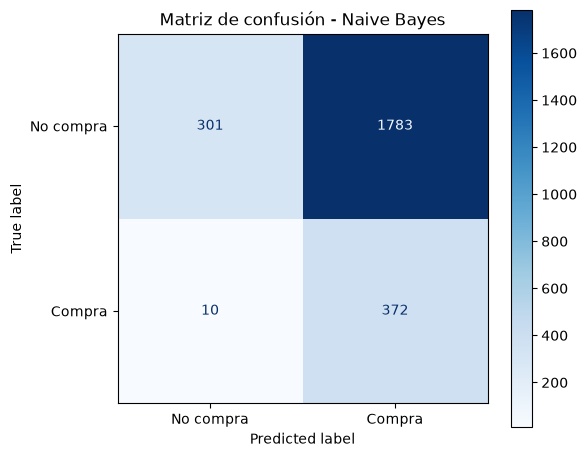

In [30]:
graficar_matriz_confusion('Naive Bayes', y_testclass, pred_nb)

<b>Interpretación de la Matriz de Confusión</b>

La matriz muestra cómo clasificó el modelo las 2466 sesiones de prueba. De las 2084 sesiones en las que el usuario no compró, el modelo solo identificó correctamente 301 (TN) y se equivocó en 1783, que marcó como compra (FP). En cambio, de las 382 sesiones con compra real, detectó 372 (TP) y solo dejó pasar 10 (FN). Es decir, el modelo casi nunca se equivoca con quienes sí compran, pero lo logra porque etiqueta como compra a la gran mayoría de las sesiones.

Esto se ve en el color de la matriz: la celda más oscura, la de falsos positivos, concentra el mayor número de errores. En la práctica, el modelo predijo compra en 2155 sesiones (372 + 1783), pero solo 372 eran compras reales, por lo que casi 5 de cada 6 alertas serían alertas falsas de compra. Aunque detecta casi todas las compras, el modelo no distingue bien entre quien compra y quien no.

<b>Justificación de los Resultados de Naive Bayes</b>

Los resultados obtenidos con el modelo no son apropiados por varias razones propias del algoritmo y de los datos utilizados. Naive Bayes Gaussiano estima la probabilidad de cada clase multiplicando las probabilidades individuales de cada variable, y esto solo es válido si se cumplen dos condiciones: que las variables sean condicionalmente independientes entre sí dada la clase, y que las variables numéricas sigan una distribución normal dentro de cada clase. En este conjunto de datos ninguno de los dos se cumple de forma razonable.

En primer lugar, la condicional de independencia se viola por la correlación elevada entre varias variables, como se observó en el análisis exploratorio: BounceRates y ExitRates tienen una correlación de 0.91, y ProductRelated y ProductRelated_Duration de 0.86. Cuando dos variables aportan casi la misma información, el modelo la cuenta dos veces como si fueran evidencias independientes, lo que sobreestima el peso de esas características. Este efecto puede ayudar a explicar por qué el modelo clasificó el 87 % de las sesiones como compra.

En segundo lugar, la condición de normalidad tampoco se cumple. Las variables numéricas presentan distribuciones muy sesgadas, con muchos valores cercanos a cero y algunas sesiones extremas (por ejemplo, ProductRelated llega a 705 páginas con una media de 31.7). Además, el preprocesamiento de dummificiación con OneHotEncoder generó numerosas columnas binarias a partir de Month, VisitorType, Weekend, OperatingSystems, Browser, Region y TrafficType. Una variable binaria no puede seguir una distribución normal, y las categorías poco frecuentes producen columnas casi siempre en cero con una varianza muy pequeña dentro de cada clase. Cuando el modelo evalúa esas columnas, pequeñas diferencias generan probabilidades extremas que distorsionan la decisión final.

En conjunto, estos factores hacen que las probabilidades que calcula el modelo sean poco confiables y que tienda a clasificar casi todas las sesiones en una sola clase, lo que explica el recall de 0.97 junto con una precisión de 0.17 y una exactitud de 0.27. Para verificarlas se podría repetir el entrenamiento eliminando las variables redundantes (por ejemplo, ExitRates y ProductRelated_Duration), usar otro algoritmo para las variables categóricas o combinar tipos de variables con modelos distintos.

<b>Resultados Evaluativos de Arboles Decisorios</b>

In [31]:
m_dt = comparar_manual_vs_sklearn("Árbol de Decisión", y_testclass, pred_dt)

=== Árbol de Decisión ===
TN=1990  FP=94  FN=149  TP=233


,Manual,scikit-learn,Diferencia
Accuracy,0.9015,0.9015,0.0
Precision,0.7125,0.7125,0.0
Recall,0.6099,0.6099,0.0
F1,0.6573,0.6573,0.0


In [32]:
print("Árbol de Decisión\n", classification_report(y_testclass, pred_dt, target_names=['No compra', 'Compra']))

Árbol de Decisión
               precision    recall  f1-score   support

   No compra       0.93      0.95      0.94      2084
      Compra       0.71      0.61      0.66       382

    accuracy                           0.90      2466
   macro avg       0.82      0.78      0.80      2466
weighted avg       0.90      0.90      0.90      2466



<b>Interpretación de las Métricas de Árboles Decisorios</b>

El Árbol de Decisión muestra un desempeño adecuado y es una opción apropiada para este problema. Sobre las 2466 sesiones de prueba, el modelo clasificó correctamente 1990 sesiones sin compra (TN) y 233 sesiones con compra (TP), con 94 falsos positivos y 149 falsos negativos. Su exactitud (accuracy) fue de 90.15 %, superior al porcentaje que alcanzaría un modelo que siempre predijera <code>No compra</code>.

En la clase de interés, <code>Compra</code>, la precisión fue de 71.25 %, es decir que cuando el modelo predice una compra, acierta en 7 de cada 10 casos. El recall (exhaustividad) fue de 60.99 %, es decir, detecta alrededor del 61 % de las compras reales y deja pasar el 39 % restante. El F1-score de 0.6573 resume este equilibrio y refleja un desempeño aceptable, aunque mejorable.

En la clase <code>No compra</code> el desempeño es mejor, con precisión de 0.93, recall de 0.95 y F1 de 0.94. Esto se debe a que esta clase representa el 84.5 % de los datos y el modelo tiene más ejemplos para aprender sus patrones. Los promedios del reporte de clasificación lo reflejan: el promedio ponderado (0.90 en las tres métricas) es alto porque hay más ejemplares de esta clase, mientras que el promedio macro (precisión 0.82, recall 0.78, F1 0.80) es más bajo porque da el mismo peso a ambas.

En conjunto, el árbol es confiable para descartar sesiones sin intención de compra y razonablemente preciso al identificar compradores. Su principal limitación es el recall de la clase <code>Compra</code>, al final si el negocio busca no perder oportunidades de venta, casi 4 de cada 10 compras pasarían sin ser detectadas.

<b>Matriz de Confusión de Árbol de Decisión</b>

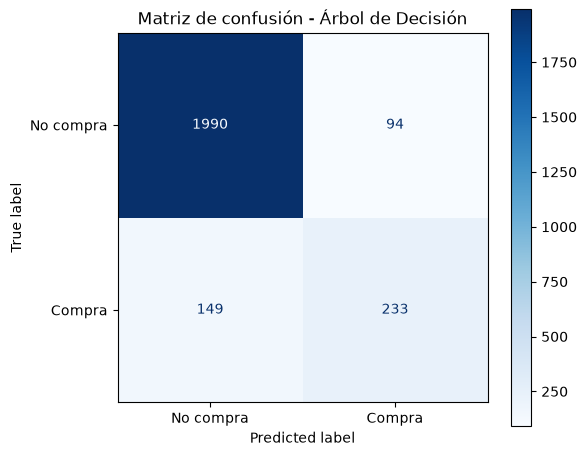

In [33]:
graficar_matriz_confusion('Árbol de Decisión', y_testclass, pred_dt)

<b>Interpretación de la Matriz de Confusión</b>

La matriz muestra que el Árbol de Decisión clasificó correctamente la gran mayoría de las sesiones sin compra: de las 2084 sesiones en las que el usuario no compró, acertó en 1990 (TN) y solo se equivocó en 94, que marcó como compra (FP). Esto se refleja en el color de la matriz, donde la celda más oscura corresponde a los verdaderos negativos. En las sesiones con compra real, el modelo detectó 233 de las 382 (TP) y dejó pasar 149 (FN).

El árbol mantiene un equilibrio entre ambos tipos de error: de las 327 sesiones que predijo como compra (233 + 94), 233 eran reales, por lo que 7 de cada 10 alertas de posibles compras son correctas. Su punto débil son los falsos negativos, ya que casi 4 de cada 10 compras reales no son detectadas. Esto indica que el modelo es confiable cuando predice una compra, pero todavía pierde una parte importante de las oportunidades de venta.

<b>Justificación del Árbol de Decisión</b>

El Árbol de Decisión obtuvo mejores resultados porque su forma de clasificar divide los datos mediante reglas del tipo “si la variable es mayor que cierto valor”, que no exigen independencia ni normalidad. Una variable redundante simplemente deja de ser útil después de usarse en una división, en lugar de contar varias veces como evidencia, y las variables binarias y las numéricas sesgadas se manejan sin problema, ya que el árbol solo busca el mejor punto de corte. Además, el árbol puede capturar relaciones no lineales y combinaciones entre variables. La decisión de compra no depende de una sola característica, sino de interacciones entre ellas, como un número alto de páginas de producto combinado con una tasa de salida baja. Mientras Naive Bayes suma evidencias de cada variable por separado, el árbol evalúa condiciones encadenadas, lo que le permite separar mejor a quienes compran de quienes no.

Por último, las restricciones de profundidad (max_depth) y de tamaño mínimo de hoja (min_samples_leaf) evitaron que el árbol memorizara casos particulares del entrenamiento. Aun así, el árbol tiene una limitación: su recall de 0.61 en la clase <code>Compra</code> muestra que no detecta cerca del 40 % de las compras reales, probablemente por el desbalance de las clases. Por lo tanto, el árbol es una buena opción pero todavia tiene margen de mejora.

<h3>1.7 Validación Estratificada Cruzada</h3>

Para realizar la validación cruzada estratificada se utiliza un objeto <code>StratifiedKFold</code>, que divide el conjunto de entrenamiento en 5 partes (folds). En cada iteración, 4 partes se usan para entrenar el modelo y la parte restante para validarlo, y el proceso se repite hasta que cada parte ha servido una vez como validación. De este modo, todos los datos participan tanto en el entrenamiento como en la validación, y las métricas finales se obtienen promediando los 5 resultados.

La estratificación garantiza que cada parte conserve la misma proporción de clases que el conjunto original (aproximadamente 84.5 % de sesiones sin compra y 15.5 % con compra). Esto es importante porque los datos están desbalanceados, si la división fuera completamente aleatoria, algunos folds podrían quedar con una proporción de compras muy distinta a la real, lo que haría que las métricas variaran más entre folds y fueran menos representativas. En un caso extremo, un fold podría tener muy pocos registros de la clase <code>Compra</code>, o ninguno, y las métricas de esa clase no se podrían calcular de forma confiable. Al estratificar, cada fold contiene una muestra representativa de ambas clases y los resultados son más estables y comparables.

In [34]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall', 'f1': 'f1'}
resultados_cv = {}

<b>Funciones Auxiliares para Validación Cruzada</b>

<b>Nombre:</b> validar_modelo <br>
<b>Argumentos:</b> <br>
    <b>(String) nombre:</b> Representa el nombre del modelo que se va a utilizar en la comparación. <br>
    <b>(GaussianNB | DecisionTreeClassifier) modelo:</b> Representa el modelo que se va a evaluar. <br>
<b>Objetivo: </b> Mostrar una tabla de métricas que describen un modelo al realizar una validación cruzada. <br>
<b>Retorno:</b> -

In [35]:
def validar_modelo(nombre, modelo):
    cv = cross_validate(modelo, X_trainclass, y_trainclass, cv=skf, scoring=scoring)
    resultados_cv[nombre] = cv
    print(f"--- {nombre} ---")
    por_fold = pd.DataFrame({m: cv[f'test_{m}'] for m in scoring},
                            index=[f'Fold {i}' for i in range(1, 6)])
    por_fold.loc['Media'] = por_fold.mean()
    por_fold.loc['Desv. est.'] = por_fold.iloc[:5].std()
    display(por_fold.round(4))

<b>Validación Cruzada con Naive Bayes</b>

In [36]:
validar_modelo('Naive Bayes', modelo_nb)

--- Naive Bayes ---


,accuracy,precision,recall,f1
Fold 1,0.2686,0.1722,0.9803,0.2930
Fold 2,0.2894,0.1764,0.9803,0.2990
Fold 3,0.2737,0.1732,0.9803,0.2944
Fold 4,0.2874,0.1780,0.9935,0.3019
Fold 5,0.3103,0.1809,0.9803,0.3054
Media,0.2859,0.1761,0.9830,0.2987
Desv. est.,0.0163,0.0035,0.0059,0.0051


<b>Interpretación de los Resultados de CV por Naive Bayes</b>

La validación cruzada muestra que Naive Bayes tiene un desempeño deficiente y muy uniforme. Las medias fueron de 0.2859 en exactitud, 0.1761 en precisión, 0.9830 en recall y 0.2987 en F1, y ningún fold se aleja de este patrón: la exactitud oscila entre 0.2686 y 0.3103, y el recall se mantiene cerca de 0.98 en todos. Las desviaciones estándar son bajas (por ejemplo, ±0.0035 en precisión y ±0.0051 en F1), lo que indica que el modelo se comporta igual sin importar cómo se particionen los datos. Esta estabilidad no es una ventaja, porque confirma que el problema es sistemático y no resultado de una división desafortunada.

El recall alto es engañoso, ya que el modelo logra detectar casi todas las compras únicamente porque clasifica la mayoría de las sesiones como compra. Esto se refleja en una precisión de 0.1761. Además, las métricas son prácticamente iguales a las obtenidas en el conjunto de prueba, por lo que el desempeño no cambia al evaluar datos nuevos. En conjunto, la validación cruzada confirma que Naive Bayes no es adecuado para este problema, lo cual es coherente con la validación realizada anteriormente.

<b>Validación Cruzada con Árbol de Decisión</b>

In [37]:
validar_modelo('Árbol de Decisión', modelo_dt)

--- Árbol de Decisión ---


,accuracy,precision,recall,f1
Fold 1,0.8779,0.6088,0.5869,0.5977
Fold 2,0.8976,0.7085,0.5738,0.6341
Fold 3,0.8900,0.6982,0.5082,0.5882
Fold 4,0.9088,0.7480,0.6209,0.6786
Fold 5,0.9077,0.7158,0.6689,0.6915
Media,0.8964,0.6959,0.5917,0.6380
Desv. est.,0.0129,0.0521,0.0594,0.0464


<b>Interpretación de los Resultados de CV por Árboles de Decisión</b>

La validación cruzada muestra que el Árbol de Decisión tiene un desempeño sólido y consistente. Las medias fueron de 0.8964 en exactitud, 0.6959 en precisión, 0.5917 en recall y 0.6380 en F1. La exactitud es muy estable entre folds (entre 0.8779 y 0.9088, con una desviación de ±0.0129). Las métricas de la clase “Compra” varían más: la precisión oscila entre 0.6088 y 0.7480, el recall entre 0.5082 y 0.6689 y el F1 entre 0.5882 y 0.6915, con desviaciones de ±0.046 a ±0.059. Esto es esperable, ya que cada fold contiene pocas compras y pequeños cambios en los casos de validación afectan estas métricas.

Los resultados de la validación cruzada son muy cercanos a los obtenidos en el conjunto de prueba. Todas las métricas de prueba quedan dentro del rango observado entre folds y a menos de una desviación estándar de la media, lo que indica que el modelo generaliza bien y no muestra señales de sobreajuste. La limitación principal es el recall, cercano a 0.59, es decir, el árbol deja pasar alrededor del 40 % de las compras reales.

<b>Resumen de Resultados</b>

In [38]:
resumen_cv = pd.DataFrame({
    nombre: {m: f"{cv[f'test_{m}'].mean():.3f} ± {cv[f'test_{m}'].std():.3f}" for m in scoring}
    for nombre, cv in resultados_cv.items()
})
resumen_cv

,Naive Bayes,Árbol de Decisión
accuracy,0.286 ± 0.015,0.896 ± 0.012
precision,0.176 ± 0.003,0.696 ± 0.047
recall,0.983 ± 0.005,0.592 ± 0.053
f1,0.299 ± 0.005,0.638 ± 0.042


<h3>1.8 Comparación de Modelos y Selección</h3>

Para el negocio, lo más conveniente es que el modelo identifique correctamente los verdaderos positivos, es decir, que detecte a quienes realmente van a comprar, y que a la vez mantenga controlados los falsos negativos, porque cada compra no detectada es una oportunidad de ingreso desaprovechada. Los verdaderos negativos tienen menor valor directo, ya que la clase <code>No compra</code> representa el 84.5 % de los datos y acertar en ella resulta fácil, lo que infla la exactitud sin aportar valor comercial. Los falsos positivos deben limitarse, pero su costo suele ser menor que el de una venta perdida cuando las intervenciones son baratas. Por esta razón, la métrica más apropiada para comparar los modelos es el F1-score de la clase <code>Compra</code>, que equilibra la detección de compradores (recall) con la confiabilidad de las alertas (precisión), y no la exactitud.

In [39]:
sns.set_theme(style="whitegrid")

<b>Obtensión de Resultados Generales de los Modelos (Valores Exactos)</b>

In [40]:
comparacion = pd.DataFrame({
    'Naive Bayes': {k: m_nb[k] for k in ['Accuracy', 'Precision', 'Recall', 'F1']},
    'Árbol de Decisión': {k: m_dt[k] for k in ['Accuracy', 'Precision', 'Recall', 'F1']}
}).T
display(comparacion.round(4))

,Accuracy,Precision,Recall,F1
Naive Bayes,0.2729,0.1726,0.9738,0.2933
Árbol de Decisión,0.9015,0.7125,0.6099,0.6573


<b>Obtensión de Resultados Generales de los Modelos (Visualización Gráfica)</b>

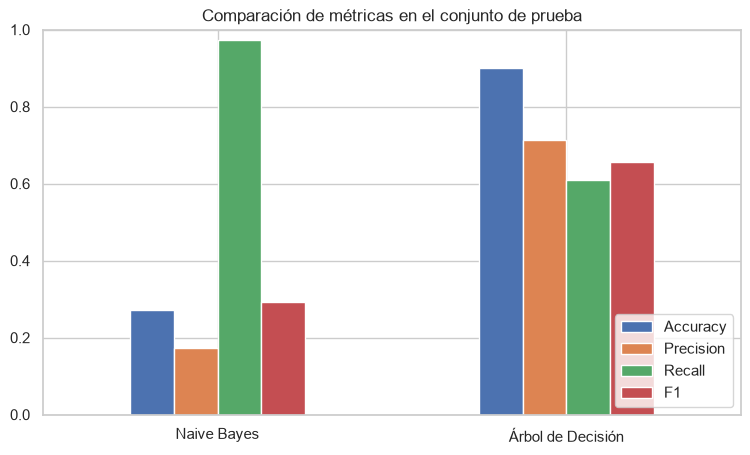

In [41]:
comparacion.plot(kind='bar', figsize=(9, 5), rot=0)
plt.title("Comparación de métricas en el conjunto de prueba")
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.show()

<b>Selección del Modelo más Apropiado</b>

Basado en los resultados analizados, el modelo más apropiado para su implementación es el Árbol de Decisión. Este algoritmo demuestra un rendimiento significativamente superior y más equilibrado que el Naive Bayes para este problema específico de clasificación de intenciones de compra en el sitio de comercio electrónico. 

La superioridad del Árbol de Decisión se evidencia de manera clara en sus métricas generales, logrando una exactitud del 90.15 %, mientras que Naive Bayes obtiene un deficiente 27.29 %, un resultado incluso peor que asumir de antemano que ninguna sesión terminará en compra. Además, el modelo de árbol alcanza una precisión del 71.25 % para la clase de compradores, lo que significa que acierta en siete de cada diez predicciones positivas. En contraste, Naive Bayes presenta una precisión de apenas 17.26 %, lo que lo lleva a generar 1783 falsos positivos al etiquetar incorrectamente casi el 87 % de todas las sesiones de prueba como compras inminentes. 

La implementación del Árbol de Decisión generaría un impacto muy positivo en el negocio al permitir una asignación eficiente de los recursos de marketing y ventas. Al predecir con una buena precisión qué usuarios están más propensos a concretar una venta, la empresa puede dirigir campañas específicas, ofrecer descuentos en tiempo real o proveer asistencia en vivo exclusivamente a ese segmento, optimizando así el retorno de inversión. Por el contrario, si se optara por el modelo Naive Bayes, la empresa sufriría pérdidas económicas significativas, ya que desperdiciaría recursos ofreciendo incentivos y esfuerzos comerciales a una inmensa mayoría de visitantes que realmente no tenían ninguna intención de adquirir un producto. 

A pesar de las ventajas de la implementación del Árbol de Decisión, existen consideraciones importantes al momento de tomar decisiones con este modelo implementado. Es crucial tener en cuenta que el Árbol de Decisión posee una exhaustividad (recall) del 60.99 % en la clase de compra, lo que implica que casi cuatro de cada diez compras reales pasarán desapercibidas por el sistema predictivo. El negocio deberá evaluar si este margen de oportunidades de venta no detectadas es aceptable o si requiere de estrategias complementarias para captar a esos clientes. Finalmente, dado que el análisis exploratorio reveló que el mes de noviembre concentra el mayor número de compras y conversiones debido a eventos comerciales masivos, es fundamental monitorear el modelo continuamente para garantizar que sus reglas de decisión no se encuentren sesgadas únicamente por el comportamiento de las temporadas altas y mantenga su efectividad comercial durante los meses de menor actividad.

<h3>Anexos Respecto al Árbol de Decisión</h3>

In [42]:
arbol = modelo_dt.named_steps['clf']
nombres_feat = modelo_dt.named_steps['prep'].get_feature_names_out()
importancias = pd.Series(arbol.feature_importances_, index=nombres_feat).sort_values(ascending=False).head(10)

<b>Top de Carácteristicas de Importancia</b>

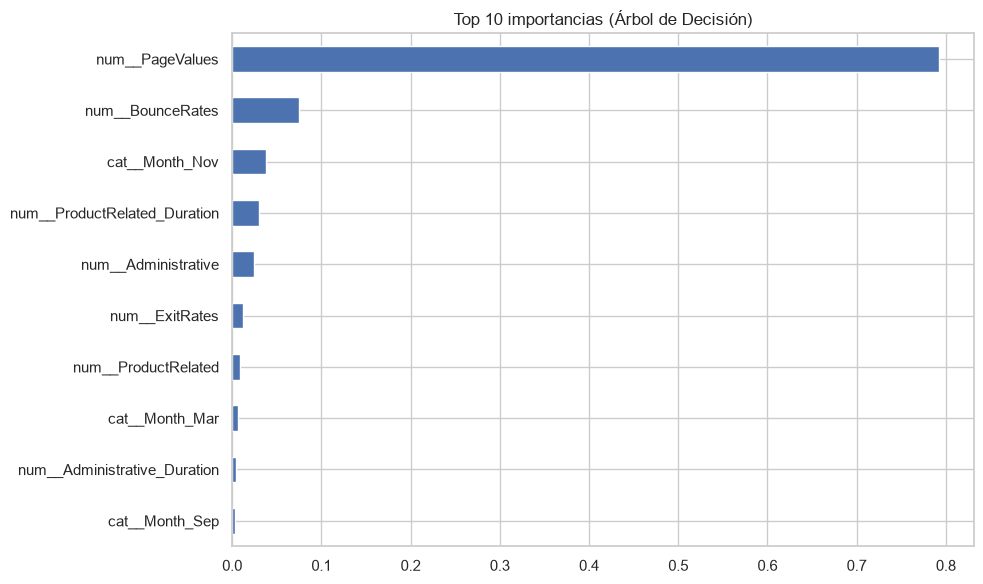

In [43]:
plt.figure(figsize=(10, 6))
importancias[::-1].plot(kind='barh', title="Top 10 importancias (Árbol de Decisión)")
plt.tight_layout()
plt.show()

<b>Primeros 3 Niveles del Árbol de Decisión</b>

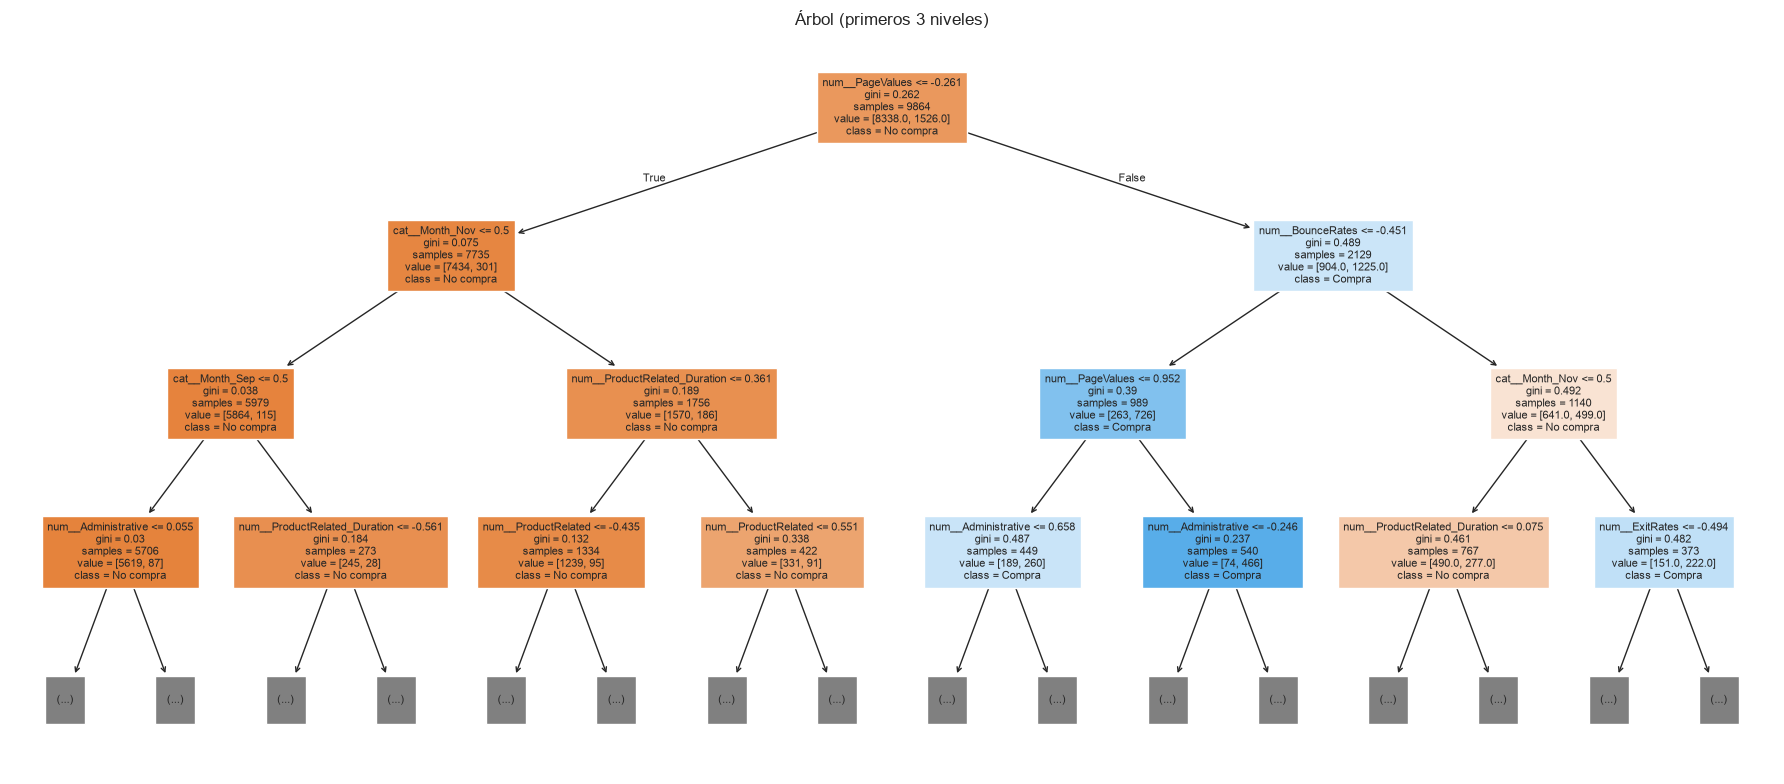

In [44]:
plt.figure(figsize=(18, 8))
plot_tree(arbol, max_depth=3, feature_names=nombres_feat, class_names=['No compra', 'Compra'],
          filled=True, fontsize=8)
plt.title("Árbol (primeros 3 niveles)")
plt.tight_layout()
plt.show()

<h3>1.9 Pregunta de Análisis</h3>
<p><b>¿Qué consecuencias podrían tener los falsos positivos y los falsos negativos en el contexto del problema?</b>

Los falsos positivos ocurren cuando el modelo clasifica erróneamente una sesión como una compra inminente, lo que podría impactar directamente en cómo la empresa decide asignar recursos de forma más eficiente. Al predecir falsas conversiones, el negocio podría malgastar presupuesto al dirigir una campaña promocional, descuentos agresivos o esfuerzos de atención al cliente hacia visitantes que únicamente están navegando sin intención real de adquirir productos. Este tipo de error no solo debilita los márgenes comerciales, sino que también afecta la cadena de suministro al alterar decisiones operativas clave, como determinar cuánto inventario preparar basándose en una expectativa de demanda que no es realista y se fundamenta en patrones que no suceden.

Por otro lado, los falsos negativos suceden cuando el sistema asume que el usuario abandonará el sitio sin comprar, fallando en detectar a un cliente que realmente está dispuesto a completar la transacción. Esta equivocación representa una pérdida directa de oportunidades estratégicas para el negocio, ya que impide que la plataforma de comercio electrónico aplique tácticas en tiempo real orientadas a retener clientes potenciales o asegurar ventas que podrían requerir asistencia, dificultando así el objetivo primordial de maximizar la tasa de conversión general del sitio. Al dejar pasar sin intervención a compradores legítimos la empresa pierde información valiosa para optimizar la experiencia del usuario y fortalecer la lealtad de quienes verdaderamente aportan ingresos. 

<b>¿Qué métrica considerarías más importante y por qué?</b>

En este escenario, el F1-score destaca como la métrica más valiosa para tomar decisiones comerciales. El motivo principal es que nuestros datos están muy desequilibrados: la gran mayoría de las visitas, un 84.5 %, termina sin una compra, mientras que solo un pequeño grupo del 15.5 % realmente adquiere un producto. Si nos guiáramos únicamente por la "exactitud" (el total de aciertos generales), tendríamos una visión equivocada de la realidad, ya que el sistema podría fallar constantemente en detectar las ventas reales y, aun así, mostrar un porcentaje de éxito aparentemente alto. 

El F1-score soluciona este problema funcionando como una balanza entre dos indicadores clave: la precisión y el recall (o sensibilidad). En palabras sencillas, esta métrica busca que exista un equilibrio sano entre tener la razón cuando el modelo asegura que alguien va a comprar (precisión) y tener la capacidad de atrapar a la mayor cantidad posible de esos compradores reales dentro de la tienda (recall). 

Al priorizar esta métrica equilibrada, el negocio se protege de caer en dos extremos peligrosos. Por una parte, evita generar un exceso de falsas alarmas (falsos positivos), lo que detiene el desperdicio de dinero en campañas o descuentos dirigidos a usuarios que nunca tuvieron intención de comprar. Por otra parte, garantiza que el sistema sea lo suficientemente agudo como para no dejar escapar a los clientes que sí están listos para finalizar una transacción (falsos negativos), cuidando así las ventas y el crecimiento de la empresa. 

</p>

<h2>2. Modelos de Regresión</h2>
<hr>
<p>
A diferencia de la clasificación, que asigna cada observación a una categoría, los modelos de regresión estiman un valor numérico continuo. En el ámbito empresarial se usan para anticipar cantidades como las ventas, la demanda de un servicio o los ingresos del próximo mes, lo que ayuda a planificar los recursos con antelación.
    
En esta sección se desarrolla un problema de regresión con el conjunto de datos Seoul Bike Sharing Demand, que registra el alquiler de bicicletas por hora junto con las condiciones del clima y del calendario. El objetivo es estimar cuántas bicicletas se alquilarán en cada hora. Para ello se explora la fuente de datos y las relaciones entre sus variables, se describe el preprocesamiento aplicado y se construyen dos modelos, Regresión Lineal Múltiple y Árbol de Decisión para Regresión, que se comparan mediante MAE, RMSE y R². La sección cierra con un análisis de qué tan confiables son las predicciones para apoyar decisiones reales.
</p>

In [45]:
df_regresion = pd.read_csv("SeoulBikeData.csv", encoding="latin1")

<h3>2.1 Exploración de la Fuente de Datos</h3>
<p>Antes de iniciar el proceso de preparación es necesario conocer ciertos aspectos de la fuente de datos. En este caso se evaluaron los siguientes aspectos para saber el nivel de calidad de los datos existentes y si es necesario aplicar alguna transformación para realizar correcciones a alguno de los datos.</p>

<b>Inspección Inicial Básica</b>

In [46]:
print("Vista previa de los primeros 5 registros:")
df_regresion.head()

Vista previa de los primeros 5 registros:


,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [47]:
print("Forma de la fuente de datos: (Filas x Columnas)",df_regresion.shape)

Forma de la fuente de datos: (Filas x Columnas) (8760, 14)


<b>Aplicación de Correcciones Estéticas</b>

In [48]:
df_regresion.columns = ['Date','RentedBikeCount','Hour','Temperature','Humidity','WindSpeed',
                        'Visibility','DewPoint','SolarRadiation','Rainfall','Snowfall',
                        'Seasons','Holiday','FunctioningDay']

df_regresion['Date'] = pd.to_datetime(df_regresion['Date'], format='%d/%m/%Y')

<b>Consideraciones de Análisis de Calidad de los Datos</b>
<ul>
    <li>Validar la existencia de los valores nulos.</li>
    <li>Validar que los tipos de datos sean consistentes con la información que almacenan.</li>
    <li>Validar que las variables categóricas que almacenan texto no tengan conflictos tipográficos.</li>
</ul>

In [49]:
print("Cantidad de valores vacios en cada columna:")
df_regresion.isna().sum()

Cantidad de valores vacios en cada columna:


Date               0
RentedBikeCount    0
Hour               0
Temperature        0
Humidity           0
WindSpeed          0
Visibility         0
DewPoint           0
SolarRadiation     0
Rainfall           0
Snowfall           0
Seasons            0
Holiday            0
FunctioningDay     0
dtype: int64

In [50]:
print("Información de los tipos de datos y valores no nulos:")
df_regresion.info()

Información de los tipos de datos y valores no nulos:
<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Date             8760 non-null   datetime64[us]
 1   RentedBikeCount  8760 non-null   int64         
 2   Hour             8760 non-null   int64         
 3   Temperature      8760 non-null   float64       
 4   Humidity         8760 non-null   int64         
 5   WindSpeed        8760 non-null   float64       
 6   Visibility       8760 non-null   int64         
 7   DewPoint         8760 non-null   float64       
 8   SolarRadiation   8760 non-null   float64       
 9   Rainfall         8760 non-null   float64       
 10  Snowfall         8760 non-null   float64       
 11  Seasons          8760 non-null   str           
 12  Holiday          8760 non-null   str           
 13  FunctioningDay   8760 non-null   str           
dt

In [51]:
print("Validación de los valores de las variables categóricas:")
print("Valores de Seasons: ",df_regresion["Seasons"].unique())
print("Valores de Holiday: ",df_regresion["Holiday"].unique())
print("Valores de FunctioningDay: ",df_regresion["FunctioningDay"].unique())

Validación de los valores de las variables categóricas:
Valores de Seasons:  <ArrowStringArray>
['Winter', 'Spring', 'Summer', 'Autumn']
Length: 4, dtype: str
Valores de Holiday:  <ArrowStringArray>
['No Holiday', 'Holiday']
Length: 2, dtype: str
Valores de FunctioningDay:  <ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str


<b>Consideraciones de la Exploración Estadística</b>
<ul>
    <li>Visualizar la media, valor mínimo, valor máximo y el rango de valores que tienen algunas columnas numéricas importantes.</li>
    <li>Utilizar visualizaciones para conocer algunos patrones que pueden ser de interes.</li>
    <li>Validar la distribución de los datos de la variable objetivo para conocer como los datos se distribuiran antes de realizar la estratificación en el modelo.</li>
</ul>

In [52]:
descripcion_estadistica_numerica(df_regresion,"RentedBikeCount")

Media de RentedBikeCount : 704.6020547945205
Valor Mínimo de RentedBikeCount : 0
Valor Máximo de RentedBikeCount : 3556
Rango de Valores en RentedBikeCount (maximo - minimo): 3556
Desviación Estándar en RentedBikeCount 644.9974677392156


In [53]:
descripcion_estadistica_numerica(df_regresion,"Temperature")

Media de Temperature : 12.882922374429223
Valor Mínimo de Temperature : -17.8
Valor Máximo de Temperature : 39.4
Rango de Valores en Temperature (maximo - minimo): 57.2
Desviación Estándar en Temperature 11.944825230027947


In [54]:
descripcion_estadistica_numerica(df_regresion,"Visibility")

Media de Visibility : 1436.825799086758
Valor Mínimo de Visibility : 27
Valor Máximo de Visibility : 2000
Rango de Valores en Visibility (maximo - minimo): 1973
Desviación Estándar en Visibility 608.2987119840188


In [55]:
descripcion_estadistica_numerica(df_regresion,"Rainfall")

Media de Rainfall : 0.14868721461187215
Valor Mínimo de Rainfall : 0.0
Valor Máximo de Rainfall : 35.0
Rango de Valores en Rainfall (maximo - minimo): 35.0
Desviación Estándar en Rainfall 1.1281929687321486


In [56]:
descripcion_estadistica_numerica(df_regresion,"Snowfall")

Media de Snowfall : 0.07506849315068492
Valor Mínimo de Snowfall : 0.0
Valor Máximo de Snowfall : 8.8
Rango de Valores en Snowfall (maximo - minimo): 8.8
Desviación Estándar en Snowfall 0.4367461811249922


In [57]:
print("Distribución de RentedBikeCount según los Valores de FunctioningDay:")
print(df_regresion.groupby("FunctioningDay")["RentedBikeCount"].sum())

Distribución de RentedBikeCount según los Valores de FunctioningDay:
FunctioningDay
No           0
Yes    6172314
Name: RentedBikeCount, dtype: int64


In [58]:
print("Distribución de RentedBikeCount según los Valores de Holiday:")
df_regresion.groupby("Holiday")["RentedBikeCount"].sum()

Distribución de RentedBikeCount según los Valores de Holiday:


Holiday
Holiday        215895
No Holiday    5956419
Name: RentedBikeCount, dtype: int64

Text(0.5, 1.0, 'Cantidad de Bicicletas Rentadas vs Cantidad de Nieve en cm Caida')

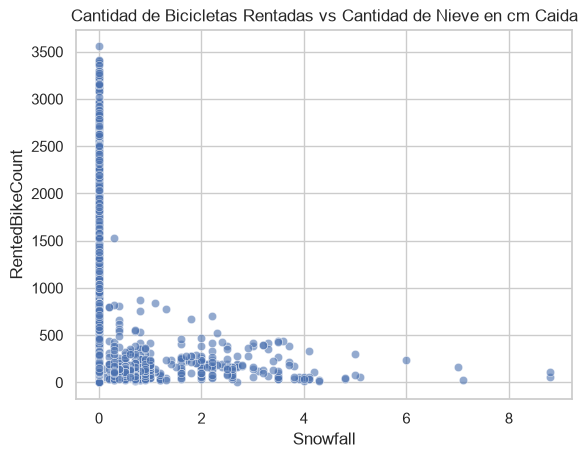

In [59]:
(sns.scatterplot(data=df_regresion, x='Snowfall', y='RentedBikeCount', alpha=0.6)).set_title("Cantidad de Bicicletas Rentadas vs Cantidad de Nieve en cm Caida")

Text(0.5, 1.0, 'Cantidad de Bicicletas Rentadas vs Cantidad de Lluvia en mm Caida')

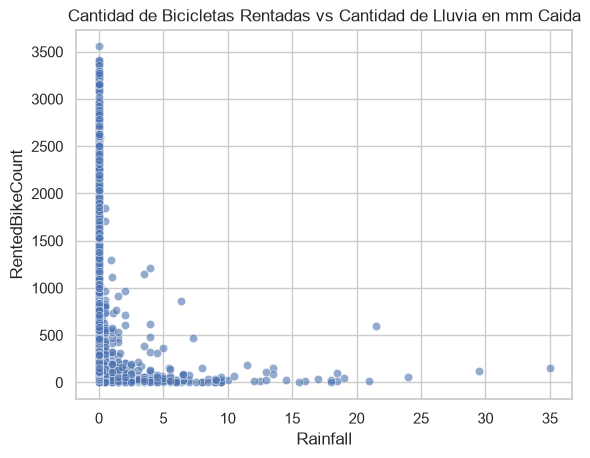

In [60]:
(sns.scatterplot(data=df_regresion, x='Rainfall', y='RentedBikeCount', alpha=0.6)).set_title("Cantidad de Bicicletas Rentadas vs Cantidad de Lluvia en mm Caida")

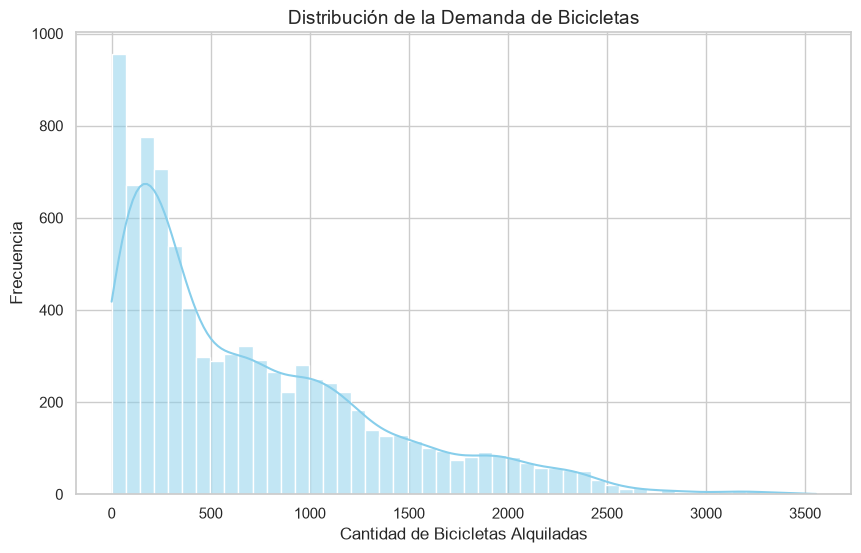

In [61]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df_regresion, x='RentedBikeCount', kde=True, bins=50, color="skyblue")
plt.title('Distribución de la Demanda de Bicicletas', fontsize=14)
plt.xlabel('Cantidad de Bicicletas Alquiladas')
plt.ylabel('Frecuencia')
plt.show()

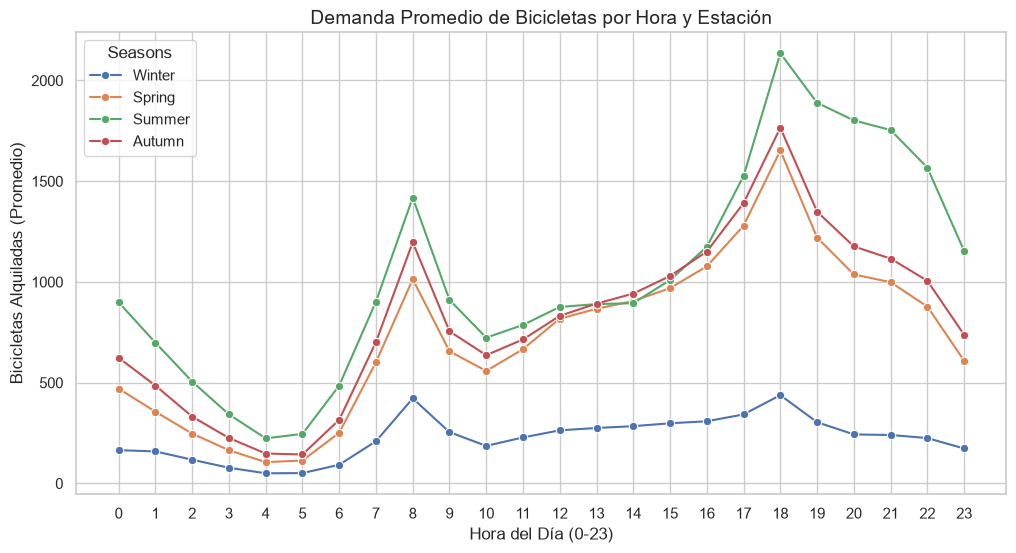

In [62]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=df_regresion, x='Hour', y='RentedBikeCount', hue='Seasons', errorbar=None, marker="o")
plt.title('Demanda Promedio de Bicicletas por Hora y Estación', fontsize=14)
plt.xlabel('Hora del Día (0-23)')
plt.ylabel('Bicicletas Alquiladas (Promedio)')
plt.xticks(range(0, 24))
plt.show()

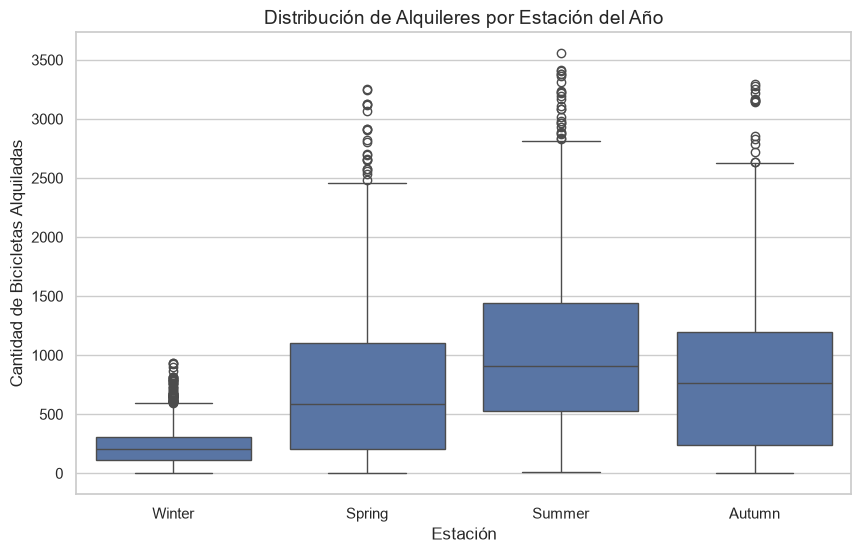

In [63]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_regresion, x='Seasons', y='RentedBikeCount')
plt.title('Distribución de Alquileres por Estación del Año', fontsize=14)
plt.xlabel('Estación')
plt.ylabel('Cantidad de Bicicletas Alquiladas')
plt.show()

<b>Conclusiones de la Exploración de la Fuente de Datos</b>

El conjunto de datos contiene 8,760 registros, correspondientes a observaciones horarias durante un año completo, y está estructurado en 14 variables. La inspección inicial confirma que el dataset tiene un alto nivel de calidad, ya que no presenta valores nulos en ninguna de sus columnas. Los tipos de datos se dividen lógicamente: la variable objetivo y las métricas horarias son enteras, los factores meteorológicos (temperatura, precipitación, radiación) son de punto flotante, y las variables de calendario como fecha, estación y festividades están almacenadas como texto. 

Desde la perspectiva temporal y categórica, el conjunto de datos abarca las cuatro estaciones del año (Primavera, Verano, Otoño, Invierno), distribuidas uniformemente a lo largo del año calendario. La mayoría de los registros corresponden a días no festivos y operativos, lo que indica que el modelo tendrá un sólido conjunto de datos de entrenamiento para la operación habitual del sistema, aunque deberá prestarse atención a cómo las excepciones (días festivos o no operativos) impactan la demanda.

En el análisis de las variables meteorológicas, se observa que la variable objetivo, el recuento de bicicletas alquiladas (Rented Bike Count), presenta fluctuaciones significativas vinculadas a los ciclos diarios (representados por la variable Hour). Las condiciones climáticas, como la temperatura (Temperature), la humedad (Humidity) y el punto de rocío (DewPoint), son factores críticos. Es previsible que exista una fuerte correlación positiva entre la temperatura y el punto de rocío, lo que podría introducir multicolinealidad en modelos de regresión lineal. Variables adicionales como la radiación solar, la velocidad del viento, la precipitación y las nevadas proporcionan un contexto ambiental completo, donde valores extremos (lluvia intensa o nieve) probablemente se asocien con una disminución drástica en la demanda. 

En conjunto, los datos están limpios y son robustos para el modelado. La predicción de la demanda de bicicletas no depende de un solo factor, sino de la compleja interacción entre la hora del día, la estación del año y las condiciones climáticas exactas. Esto justifica la necesidad de construir y comparar modelos predictivos avanzados, como la Regresión Lineal Múltiple para entender las relaciones base, y los Árboles de Decisión para Regresión (o modelos de ensamble) capaces de capturar relaciones no lineales complejas y los efectos combinados de las variables climáticas sobre la demanda. Para obtener modelos precisos, será crucial el preprocesamiento previo: aplicar codificación dummy (OneHotEncoder) a las variables estacionales y de calendario, y escalar estandarizadamente las diversas métricas climáticas.

<h3>2.2 Identificación de Variables</h3>

El conjunto de datos para este modelo de regresión contiene 8,760 registros y 14 columnas. Cada registro corresponde a una hora del sistema de bicicletas compartidas de Seúl, y como 8,760 equivale a 365 días por 24 horas, los datos cubren un año completo de mediciones. De las 14 columnas, la fuente de datos asigna el rol de característica a 13 y el de objetivo a una: “RentedBikeCount”. Esta variable, de tipo entero, indica el número de bicicletas alquiladas en cada hora y su predicción es la parte clave del problema, ya que permite estimar la demanda para mantener un suministro estable de bicicletas y reducir el tiempo de espera del público.

Un primer grupo de variables describe el momento en que ocurre cada registro. “Date” (fecha) indica el día del año y “Hour” (entero) señala la hora del día. A ellas se suman “Seasons” (texto), que indica la estación del año (invierno, primavera, verano u otoño), y “Holiday” (texto), que señala si ese día es feriado o no. Por último, “Functioning Day” (texto) actúa como una característica adicional que indica si la hora corresponde a un periodo en que el sistema de alquiler estaba operativo.

El resto de las variables, todas con rol de característica, describe las condiciones del clima en cada hora. “Temperature” (decimal) es la temperatura en grados Celsius y “DewPoint” (decimal) es el punto de rocío, también en grados Celsius. “Humidity” (entero) mide la humedad en porcentaje y “WindSpeed” (decimal) la velocidad del viento en metros por segundo. “Visibility” (entero) indica qué tan lejos se puede ver, en unidades de 10 metros, y “SolarRadiation” (decimal) mide la radiación solar en MJ/m². Finalmente, “Rainfall” (decimal) registra la precipitación en milímetros y “Snowfall” (decimal) la nieve en centímetros.

En cuanto a sus relaciones con la demanda, lo esperable es que se alquilen más bicicletas cuando el clima es agradable y menos cuando llueve o nieva, y que la hora del día influya, con aumentos en los horarios de entrada y salida del trabajo. También hay variables que se parecen entre sí, como “Temperature” y “DewPoint”, porque ambas dependen de las condiciones del aire. Estas relaciones se comprueban con los gráficos de dispersión y las correlaciones de la exploración.

<table style="border-collapse: collapse; width: 100%;">
  <caption style="text-align: left; font-weight: bold; padding: 6px 0;">Tabla de Variables</caption>
  <thead>
    <tr>
      <th style="border: 1px solid gray; padding: 6px; text-align: left;">Nombre</th>
      <th style="border: 1px solid gray; padding: 6px; text-align: left;">Rol</th>
      <th style="border: 1px solid gray; padding: 6px; text-align: left;">Tipo</th>
      <th style="border: 1px solid gray; padding: 6px; text-align: left;">Valores Faltantes</th>
    </tr>
  </thead>
  <tbody>
    <tr><td style="border: 1px solid gray; padding: 6px;">Date</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Fecha</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">RentedBikeCount</td><td style="border: 1px solid gray; padding: 6px;">Objetivo</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Hour</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Temperature</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Decimal</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Humidity</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">WindSpeed</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Decimal</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Visibility</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">DewPoint</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Decimal</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">SolarRadiation</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Decimal</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Rainfall</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Snowfall</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Seasons</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Texto</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Holiday</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Booleano</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">FunctioningDay</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Booleano</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
  </tbody>
</table>
<i>Tabla de variables identificadas en Seoul Bike Sharing Demand (UCI).</i>

<h3> 2.3 Identificación de las Relaciones entre las Variables</h3>

Para conocer el nivel de relación que tienen las variables, se desarrollo un conjunto de gráficos para conocer como interactuan algunas variables entre sí. En este caso se evaluaron los siguientes aspectos para saber las relaciones que poseen las variables entre ellas.

<ul>
    <li>Identificar la correlación que existe entre las variables numéricas.<br></li>
    <li>Identificar la relación entre las variables climáticas y la demanda de bicicletas.<br></li>
    <li>Identificar la la relación entre la estación del año y la demanda de bicicletas.<br></li>
</ul>

Text(0.5, 1.0, 'Correlación entre métricas de renta de bicicletas')

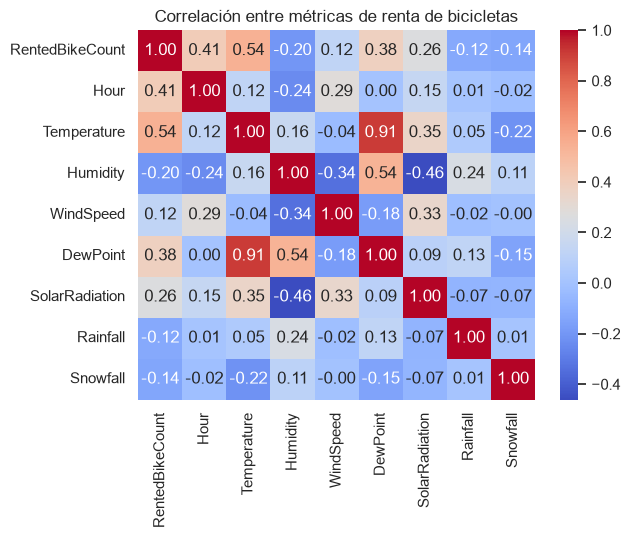

In [64]:
cols_num = ["RentedBikeCount", "Hour","Temperature","Humidity","WindSpeed","DewPoint","SolarRadiation",
            "Rainfall","Snowfall"]
sns.heatmap(df_regresion[cols_num].corr(), annot=True, cmap='coolwarm', fmt=".2f").set_title("Correlación entre métricas de renta de bicicletas")

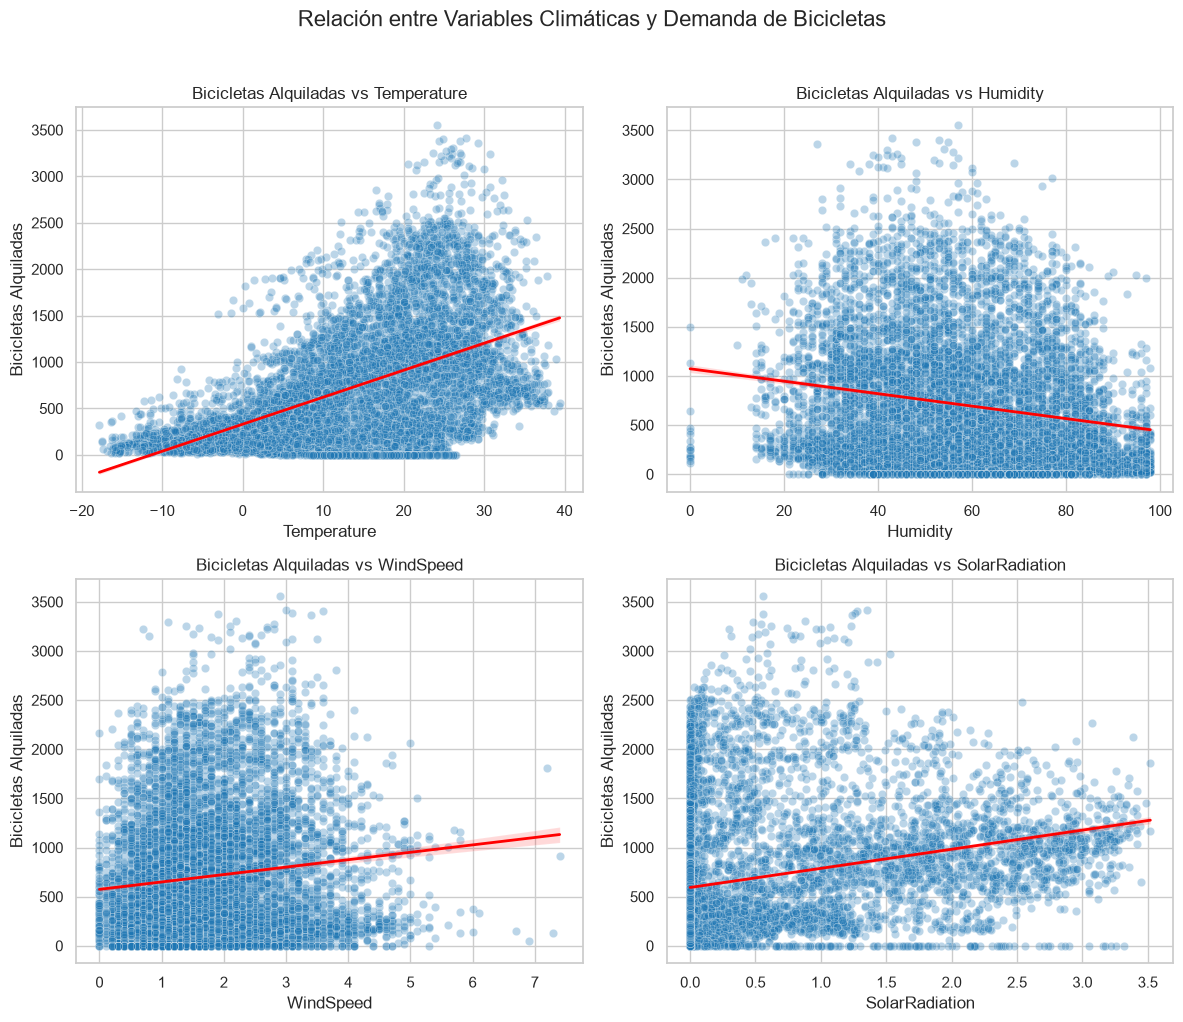

In [65]:
variables_independientes = ["Temperature", "Humidity", "WindSpeed", "SolarRadiation"]

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 10))
fig.suptitle('Relación entre Variables Climáticas y Demanda de Bicicletas', fontsize=16, y=1.02)

axes = axes.flatten()

for i, var in enumerate(variables_independientes):
    sns.scatterplot(data=df_regresion, x=var, y='RentedBikeCount', 
                    alpha=0.3, ax=axes[i], color='#1f77b4')
    
    sns.regplot(data=df_regresion, x=var, y='RentedBikeCount', 
                scatter=False, ax=axes[i], color='red', line_kws={"linewidth": 2})
    
    axes[i].set_title(f'Bicicletas Alquiladas vs {var}', fontsize=12)
    axes[i].set_ylabel('Bicicletas Alquiladas')

plt.tight_layout()
plt.show()

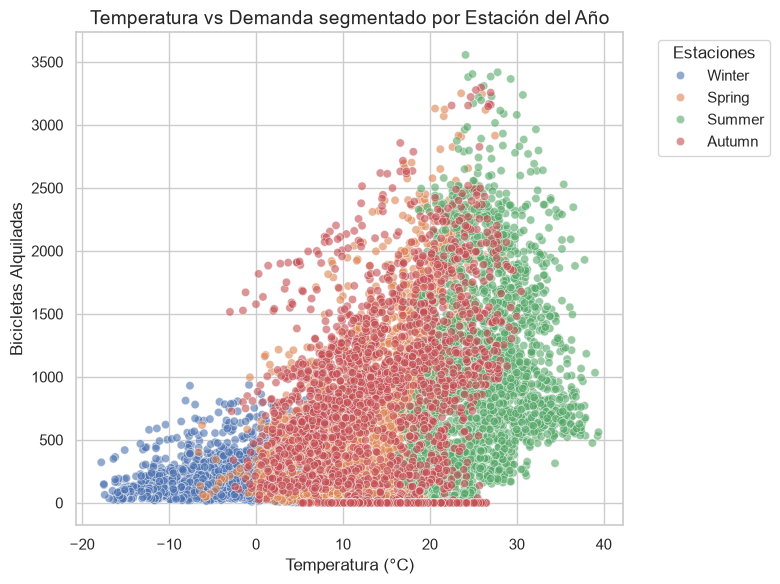

In [66]:
plt.figure(figsize=(8, 6))

sns.scatterplot(data=df_regresion, x='Temperature', y='RentedBikeCount', 
                hue='Seasons', alpha=0.6)

plt.title('Temperatura vs Demanda segmentado por Estación del Año', fontsize=14)
plt.xlabel('Temperatura (°C)')
plt.ylabel('Bicicletas Alquiladas')
plt.legend(title='Estaciones', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

<b>Conclusiones de la Identificación de Relaciones entre las Variables</b>

El análisis de los datos revela que la demanda de bicicletas compartidas está fuertemente influenciada por las condiciones climáticas, siendo la temperatura el factor predictivo más determinante. Según la matriz de correlación, la cantidad de bicicletas alquiladas ("RentedBikeCount") presenta su mayor índice de correlación positiva (0.54) con la temperatura. Esta relación directa se hace evidente en los gráficos de dispersión, donde se observa que a medida que la temperatura aumenta, la cantidad de alquileres también crece de manera sostenida. Al segmentar esta relación por estaciones del año, se distingue un comportamiento escalonado muy claro: durante el invierno, con temperaturas que frecuentemente caen por debajo de los cero grados, la demanda es mínima; en primavera y otoño, con temperaturas moderadas, la demanda incrementa consistentemente; y es durante el verano, con las temperaturas más altas, donde se registran los picos máximos de uso del servicio. 

Por el contrario, el exceso de humedad en el ambiente actúa como un factor que reduce el alquiler de bicicletas. La matriz de correlación indica una relación negativa (-0.20) entre la demanda y el porcentaje de humedad. El gráfico de dispersión correspondiente respalda esta métrica, mostrando una línea de regresión descendente que ilustra cómo los días con altos niveles de humedad, especialmente aquellos que superan el 60% u 80%, tienden a concentrar un menor volumen de bicicletas alquiladas. Este comportamiento evasivo hacia las condiciones húmedas también se refleja en las correlaciones negativas que la demanda presenta frente a otras variables de precipitación, como las nevadas (-0.14) y las lluvias (-0.12). 

Existen otras variables ambientales que benefician el uso de las bicicletas, aunque con un impacto más moderado. La radiación solar muestra una correlación de 0.26 con la cantidad de alquileres, y su gráfico de dispersión refleja una leve pero constante tendencia al alza a medida que los días son más soleados. Por su parte, la velocidad del viento tiene un efecto sumamente débil en el comportamiento de los usuarios (correlación de 0.12), presentando una línea de regresión casi plana que indica que ráfagas moderadas de viento no desmotivan de manera significativa el uso del servicio. Finalmente, fuera del aspecto netamente climático, los datos revelan que el factor temporal, específicamente la hora del día ("Hour"), juega un rol crucial en la demanda, al registrar una fuerte correlación positiva de 0.41, sugiriendo la existencia de horas pico muy marcadas a lo largo de la jornada. 

<h3>2.4 Variable Objetivo del Problema</h3>

El objetivo principal del modelo de regresión es estimar de manera precisa cuántas bicicletas se alquilarán en cada hora en el sistema de bicicletas compartidas de Seúl, utilizando la variable “RentedBikeCount” como valor a predecir. A partir de las condiciones del clima y la información del calendario, como la temperatura, la lluvia, la hora del día, la estación y los días feriados, el algoritmo debe aprender cómo influyen estos factores en la demanda. A diferencia de un problema de clasificación, aquí no se busca una categoría, sino una cantidad numérica, y lo importante es que el valor estimado se acerque lo más posible al real.

Desde un punto de vista analítico y comercial, esta predicción es valiosa porque permite que el servicio tenga las bicicletas disponibles en el momento y el lugar que se necesitan, lo que reduce el tiempo de espera de los usuarios y mantiene un suministro estable. Al identificar qué variables pesan más en la demanda, el modelo puede apoyar decisiones como cuántas bicicletas distribuir en cada franja horaria, cuándo programar el mantenimiento o cómo prepararse ante condiciones de clima adversas. Para comprobar que el modelo funciona con datos futuros, se reserva para la prueba la parte final del año, respetando el orden cronológico de los registros.


<h3>2.5 Preparación y Preprocesamiento de los Modelos</h3>

<p>
Antes de construir los modelos de regresión es necesario preparar la estructura de los datos. A diferencia del problema de clasificación, en este conjunto la información está ordenada en el tiempo (un registro por cada hora), por lo que el orden de las observaciones es parte fundamental del problema y debe conservarse correctamente. En esta primera etapa se realizan las siguientes acciones:
</p>
<ol>
    <li> Los registros se ordenan por <code>Date</code> y <code>Hour</code> y se reinicia el índice con <code>reset_index</code>. Esto garantiza que cada fila esté en su posición temporal correcta, algo necesario para que más adelante la partición entre entrenamiento y prueba respete el orden cronológico (el 80 % más antiguo para entrenar y el 20 % más reciente para evaluar), sin mezclar horas del futuro en el entrenamiento.</li>
    <li>A partir de la fecha se extrae el día de la semana (0 = lunes, 6 = domingo). La fecha completa no puede ser utilizada directamente por los modelos como un valor numérico con sentido, pero el día de la semana sí aporta información útil: la demanda de bicicletas se comporta de forma distinta en días laborales y en fines de semana, por ejemplo, por los desplazamientos al trabajo. Esta es una de las transformaciones de ingeniería de características que se aplican en este problema.</li>
</ol>

In [67]:
df_regresion = df_regresion.sort_values(['Date','Hour']).reset_index(drop=True)
df_regresion['DayOfWeek'] = df_regresion['Date'].dt.dayofweek

Luego de establecer las propiedades básicas faltantes del modelo, se define <code>y_regresion</code> con la columna RentedBikeCount, que es el valor que se desea predecir (número de bicicletas alquiladas por hora). Posteriormente, Se construye <code>X_regresion</code> con el resto de las columnas, excluyendo las siguientes:

<ul>
    <li>RentedBikeCount, porque es la variable objetivo y no puede formar parte de los datos con los que se predice.<br></li>
    <li>Date, porque ya fue utilizada para ordenar los datos y derivar <code>DayOfWeek</code>. Mantenerla no aportaría información adicional y sus valores únicos no se repiten entre entrenamiento y prueba, por lo que el modelo no podría generalizar a partir de ella.<br></li>
    <li>DewPoint (punto de rocío), porque en el análisis exploratorio mostró una correlación muy alta con Temperature. Al aportar información prácticamente redundante, se elimina para reducir la multicolinealidad, que afecta sobre todo a la Regresión Lineal al dificultar la interpretación de sus coeficientes.</li>
</ul>

In [68]:
y_regresion = df_regresion['RentedBikeCount']
X_regresion = df_regresion.drop(columns=['RentedBikeCount','Date','DewPoint'])

<b>Dummificación y Escalado Estándar de las Variables</b>

<p>
En este bloque se define cómo se transformarán las variables antes de entrenar los modelos de regresión. Primero se crea la lista <code>cat_regresion</code> con las variables categóricas: Hour, Seasons, Holiday, FunctioningDay y DayOfWeek. Aunque Hour y DayOfWeek están almacenadas como números enteros, se tratan como categorías porque su relación con la demanda no es lineal: un valor mayor no significa más bicicletas (la demanda tiene picos a las 8:00 y a las 18:00, y el lunes no es "menor" que el domingo). Luego se construye la lista <code>num_reg_final</code> con todas las columnas restantes de <code>X_regresion</code>, es decir, las variables numéricas meteorológicas (Temperature, Humidity, WindSpeed , Visibility, SolarRadiation, Rainfall y Snowfall).
</p>

<p>
Finalmente, la función <code>crear_preprocesador_reg</code> devuelve un <code>ColumnTransformer</code> que aplica una transformación distinta a cada grupo de columnas. A las variables numéricas se les aplica <b>StandardScaler</b>, que las convierte a media 0 y desviación estándar 1 para que variables con escalas muy diferentes, como Visibility (valores de miles) y Rainfall (valores cercanos a cero), tengan un peso comparable. A las categóricas se les aplica <b>OneHotEncoder</b>, que crea una columna binaria por cada categoría, de modo que no se asigne un orden artificial entre ellas. El parámetro <code>handle_unknown='ignore'</code> evita errores si en el conjunto de prueba aparece una categoría que no estaba en el entrenamiento, representándola con ceros en todas sus columnas, y <code>sparse_output=False</code> devuelve el resultado como una matriz densa, compatible con los algoritmos utilizados. Al igual que en la clasificación, la función solo define la transformación y se llama dentro de cada <code>Pipeline</code>, de manera que el escalado y la dummificación se aprenden únicamente con los datos de entrenamiento y luego se aplican a los de prueba, evitando fuga de información.
</p>

In [69]:
cat_regresion = ['Hour','Seasons','Holiday','FunctioningDay','DayOfWeek']
num_reg_final = [c for c in X_regresion.columns if c not in cat_regresion]

def crear_preprocesador_reg():
    return ColumnTransformer([
        ('num', StandardScaler(), num_reg_final),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_regresion)
    ])

<b>División de los Bloques de Entrenamiento y Prueba</b>

<p>
En este bloque se realiza la partición de los datos respetando el orden cronológico. Primero se calcula el punto de corte, <code>corte</code>, como el 80 % de la cantidad total de registros. Luego se utiliza <code>iloc</code> para dividir por posición: las filas anteriores al corte (<code>[:corte]</code>) forman el conjunto de entrenamiento y las posteriores (<code>[corte:]</code>) forman el conjunto de prueba, tanto para las variables independientes (<code>X_trainreg</code> y <code>X_testreg</code>) como para la variable objetivo (<code>y_trainreg</code> y <code>y_testreg</code>). Como los datos ya fueron ordenados por fecha y hora, el entrenamiento contiene el 80 % más antiguo y la prueba el 20 % más reciente. Esto simula el uso real del modelo, que aprende del pasado para predecir el futuro, y por esa razón no se utilizó <code>train_test_split</code> con mezcla aleatoria ni estratificación, como se hizo en la clasificación.
</p>
<p>
Las instrucciones <code>print</code> verifican que la partición se realizó como se esperaba. Las dos primeras muestran el rango de fechas que abarca cada conjunto: el entrenamiento va desde el 2017-12-01  hasta el 2018-09-18 y la prueba desde el 2018-09-19 hasta el 2018-11-30, sin solapamiento entre ambos. La última instrucción muestra la cantidad de registros de cada estación (Seasons) en el entrenamiento y en la prueba. Esta comprobación es importante porque, al no ser aleatoria la partición, los dos conjuntos no tienen la misma composición. Esto implica que el modelo deberá predecir condiciones que ha visto muy poco, lo que hace más exigente la evaluación y es una limitación que se debe considerar al interpretar los resultados.
</p>

In [70]:
corte = int(len(X_regresion) * 0.8)
X_trainreg, X_testreg = X_regresion.iloc[:corte], X_regresion.iloc[corte:]
y_trainreg, y_testreg = y_regresion.iloc[:corte], y_regresion.iloc[corte:]

In [71]:
print("Entrenamiento:", df_regresion['Date'].iloc[0].date(), "→", df_regresion['Date'].iloc[corte-1].date())
print("Prueba: ", df_regresion['Date'].iloc[corte].date(), "→", df_regresion['Date'].iloc[-1].date())
print("Seasons en el Coonjunto de Entrenamiento: \n",X_trainreg['Seasons'].value_counts(),"\nSeasons en el Conjunto de Prueba: \n", X_testreg['Seasons'].value_counts())

Entrenamiento: 2017-12-01 → 2018-09-18
Prueba:  2018-09-19 → 2018-11-30
Seasons en el Coonjunto de Entrenamiento: 
 Seasons
Spring    2208
Summer    2208
Winter    2160
Autumn     432
Name: count, dtype: int64 
Seasons en el Conjunto de Prueba: 
 Seasons
Autumn    1752
Name: count, dtype: int64


<h3>2.6 Construcción de los Modelos</h3>
<p>
Con los datos ya transformados y divididos cronológicamente, se construyen los dos modelos de regresión con <b>scikit-learn</b>. Al igual que en la clasificación, cada modelo se define dentro de un Pipeline que encadena dos pasos: primero el preprocesamiento (<code>crear_preprocesador_reg</code>, con el escalado estándar y la dummificación) y luego el algoritmo de regresión. Esto garantiza que las transformaciones se aprendan únicamente con los datos de entrenamiento y se apliquen automáticamente a los datos de prueba al momento de predecir. En cada caso se utiliza fit para entrenar con <code>X_trainreg</code> y <code>y_trainreg</code>, y predict para generar las predicciones sobre <code>X_testreg</code>, las cuales se almacenan para ser evaluadas más adelante contra los valores reales de <code>y_testreg</code>.
</p>

<b>Entrenamiento del Modelo de Regresión por Regresión Lineal Múltiple</b>
<p>
La Regresión Lineal Múltiple asume que la demanda es una combinación lineal de las variables: cada variable aporta un efecto constante, representado por un coeficiente, y la predicción se obtiene sumando esos efectos. Durante el entrenamiento, el algoritmo busca los coeficientes que minimizan la suma de los errores al cuadrado entre los valores reales y los predichos. Su principal limitación es que no captura relaciones no lineales ni interacciones entre variables (por ejemplo, que el efecto de la temperatura sea distinto a las 8:00 que a las 3:00). Por esa razón la hora se dummificó: de esta manera, cada hora recibe su propio coeficiente y el modelo puede reproducir el patrón diario de la demanda, a pesar de ser lineal.
</p>

In [72]:
modelo_lr = Pipeline([('prep', crear_preprocesador_reg()), ('reg', LinearRegression())])
modelo_lr.fit(X_trainreg, y_trainreg)
pred_lr  = modelo_lr.predict(X_testreg)

<b>Entrenamiento del Modelo de Regresión por Árboles de Decisión para Regresión</b>
<p>
El Árbol de Decisión para Regresión divide los datos mediante reglas del tipo "si la temperatura es mayor que cierto valor", y la predicción de cada grupo final (hoja) es el promedio de la demanda de los registros de entrenamiento que cayeron en él. A diferencia de la regresión lineal, no exige linealidad y captura interacciones entre variables de forma natural, como la combinación de una hora pico con una temperatura agradable. Su limitación es que solo puede predecir valores promedio que ya observó en el entrenamiento.

Siguiendo la lógica del árbol de clasificación, se limitó su complejidad con dos parámetros para evitar que memorice casos particulares del entrenamiento. <code>max_depth=10</code> restringe el árbol a un máximo de 10 niveles de decisión. <code>min_samples_leaf</code> se calcula con la función <code>calcular_min_samples_leaf</code>, que exige que cada hoja tenga al menos el 0.5 % de los datos de entrenamiento, para evitar reglas basadas en situaciones muy escasas. Por último, <code>random_state=42</code> fija la semilla para que los resultados sean reproducibles. Aunque los árboles no necesitan que las variables estén escaladas, se mantuvo el mismo preprocesador que en la regresión lineal para que ambos modelos reciban exactamente los mismos datos y la comparación sea justa.
</p>

In [73]:
modelo_dtr = Pipeline([('prep', crear_preprocesador_reg()),
                       ('reg', DecisionTreeRegressor(max_depth=10,
                               min_samples_leaf=calcular_min_samples_leaf(len(X_trainreg)),
                               random_state=42))])
modelo_dtr.fit(X_trainreg, y_trainreg)
pred_dtr = modelo_dtr.predict(X_testreg)

<b>Funciones Auxiliares para Evaluar los Modelos de Regresión</b>

<b>Nombre:</b> evaluar_regresion <br>
<b>Argumentos:</b> <br>
    <b>(String) nombre:</b> Representa el nombre del modelo que se va a evaluar, y se utiliza para identificar la fila correspondiente en la tabla de resultados. <br>
    <b>(Series) y_real:</b> Representa los valores reales de la variable objetivo en el conjunto de prueba. <br>
    <b>(Array) y_pred:</b> Representa los valores obtenidos mediante las predicciones del modelo para ese mismo conjunto de prueba. <br>
<b>Objetivo: </b> Calcular las métricas de error de un modelo de regresión: el MAE, el RMSE y el R². <br>
<b>Retorno:</b> (Dictionary) Retorna un conjunto de valores ordenados de forma clave-valor con el nombre del modelo y el resultado de cada una de las métricas.

In [74]:
def evaluar_regresion(nombre, y_real, y_pred):
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    r2 = r2_score(y_real, y_pred)
    return {'Modelo': nombre, 'MAE': mae, 'RMSE': rmse, 'R²': r2,
            'MAE / media real': mae / y_real.mean()}

<h3>2.7 Evaluación de los Modelos de Regresión</h3>
<p>
A continuación se construye la tabla comparativa con las métricas de los tres modelos sobre el conjunto de prueba. Primero se crea un <b>modelo de referencia</b> con <code>DummyRegressor(strategy='mean')</code>, que se entrena con <code>y_trainreg</code> y siempre predice el promedio de la demanda del entrenamiento, sin importar las características que se le pida estimar. No es un modelo que se pretenda utilizar, sino un punto de comparación mínimo, es decir, cualquier modelo útil debe obtener mejores resultados que simplemente predecir el promedio, y de lo contrario no estaría aprendiendo ningún patrón de los datos.

Luego se llamará a la función <code>evaluar_regresion</code> una vez por cada modelo: el modelo de referencia, la Regresión Lineal (<code>pred_lr</code>) y el Árbol de Regresión (<code>pred_dtr</code>), comparando siempre sus predicciones con los mismos valores reales (<code>y_testreg</code>). Cada llamada devuelve un diccionario con las métricas, y los tres diccionarios se reunirán en un DataFrame de pandas, usando <code>set_index('Modelo')</code> para que el nombre del modelo sea el identificador de cada fila. Finalmente, se mostrará la tabla con los valores redondeados a cuatro decimales, donde cada fila representa un modelo y cada columna una métrica (MAE, RMSE, R² y MAE / media real), lo que permitirá compararlos de forma directa.
</p>

In [75]:
base = DummyRegressor(strategy='mean').fit(X_trainreg, y_trainreg)
resultados_reg = pd.DataFrame([
    evaluar_regresion('Base (media)', y_testreg, base.predict(X_testreg)),
    evaluar_regresion('Regresión Lineal Múltiple', y_testreg, pred_lr),
    evaluar_regresion('Árbol de Regresión', y_testreg, pred_dtr)]).set_index('Modelo')
display(resultados_reg.round(4))

,MAE,RMSE,R²,MAE / media real
Modelo,,,,
Base (media),500.9994,616.8193,-0.0114,0.6618
Regresión Lineal Múltiple,256.7584,343.2263,0.6868,0.3392
Árbol de Regresión,416.2357,574.9640,0.1212,0.5499


<b>Interpretación de las Métricas</b>
<p>
El Modelo Base (media) establece la línea de referencia de rendimiento con un Error Absoluto Medio (MAE) de 500.9994 y una Raíz del Error Cuadrático Medio (RMSE) de 616.8193. El coeficiente de determinación (R²) de -0.0114 confirma que este enfoque no logra explicar la varianza de los datos, generando un error constante que representa el 66.18% de la media real. 
    
El modelo de Regresión Lineal Múltiple es el modelo más efectivo de la prueba, explicando el 68.68% de la variabilidad de la demanda (R² = 0.6868). Reduce el MAE a 256.7584 y el RMSE a 343.2263. Estas cifras demuestran una disminución del error absoluto del 48.8% en comparación con la línea base, situando el margen de equivocación en un 33.92% de la media real. 

El Árbol de Regresión muestra un poder predictivo sumamente limitado con un R² de 0.1212, lo que indica que solo captura el 12.1% de la varianza. Su MAE de 416.2357 y su RMSE de 574.9640 representan mejoras de apenas 16.9% y 6.8% respectivamente frente a la simple estimación de la media. El error promedio se mantiene alto, equivalente al 54.99% de la media real. 

En la regresión lineal, el RMSE es 1.34 veces mayor que el MAE, y en el árbol de regresión la proporción es de 1.38. Esta diferencia métrica señala que, aunque los modelos mantienen un error promedio específico, ocasionalmente cometen fallos de gran magnitud en ciertas predicciones puntuales que el RMSE penaliza de forma cuadrática. 

</p>

<b>Justificación de las Métricas</b>

La brecha de rendimiento entre la Regresión Lineal y el Árbol de Regresión se debe a una combinación crítica entre el método de partición de datos y la naturaleza matemática de cada algoritmo. Al separar los datos conservando el orden temporal (80% para entrenar y 20% para probar), el conjunto de prueba abarca meses específicos de la recta final del año. Esta división expone la incapacidad de extrapolación de los árboles de decisión, ya que son algoritmos basados en particiones espaciales que no pueden predecir valores fuera del rango exacto que procesaron durante el entrenamiento. Si en los meses de prueba surge una tendencia general distinta o temperaturas con combinaciones únicas, el árbol colapsa. La regresión lineal, por el contrario, utiliza una ecuación matemática capaz de proyectar y extrapolar tendencias hacia el futuro de manera más fluida.

El desempeño del modelo lineal mejora radicalmente debido al tratamiento de los patrones cíclicos. La demanda de bicicletas no tiene una relación lineal con la hora, pero al convertir esta métrica en variables categóricas, la Regresión Lineal Múltiple le asignó un peso o coeficiente independiente a cada franja horaria. Esto le otorgó la flexibilidad de un modelo no lineal para calcar el ciclo diario. En contraste, el árbol sufrió un sobreajuste estacional. Al utilizar una profundidad máxima de 10 (max_depth=10), el algoritmo fragmentó en exceso los datos de entrenamiento y creó reglas muy específicas para las estaciones de los primeros nueve meses. Al enfrentarse a las condiciones del último 20% del año, esas reglas rígidas perdieron validez, lo que explica su R² de 0.1212 frente a datos nuevos.

A pesar de sus diferencias, ambos modelos comparten una vulnerabilidad estructural: la carencia de memoria a corto plazo. En problemas que templan intervalos de tiempo, el mejor predictor de la demanda en la próxima hora suele ser lo que sucedió en la hora inmediatamente anterior. Esta limitación provoca que ambos algoritmos fallen gravemente ante eventos atípicos, como una tormenta repentina o una concentración masiva, lo que justifica por qué el RMSE se dispara de forma tan pronunciada en comparación con el MAE.


<b>Representación Gráfica de los Resultados Reales vs Predichos</b>

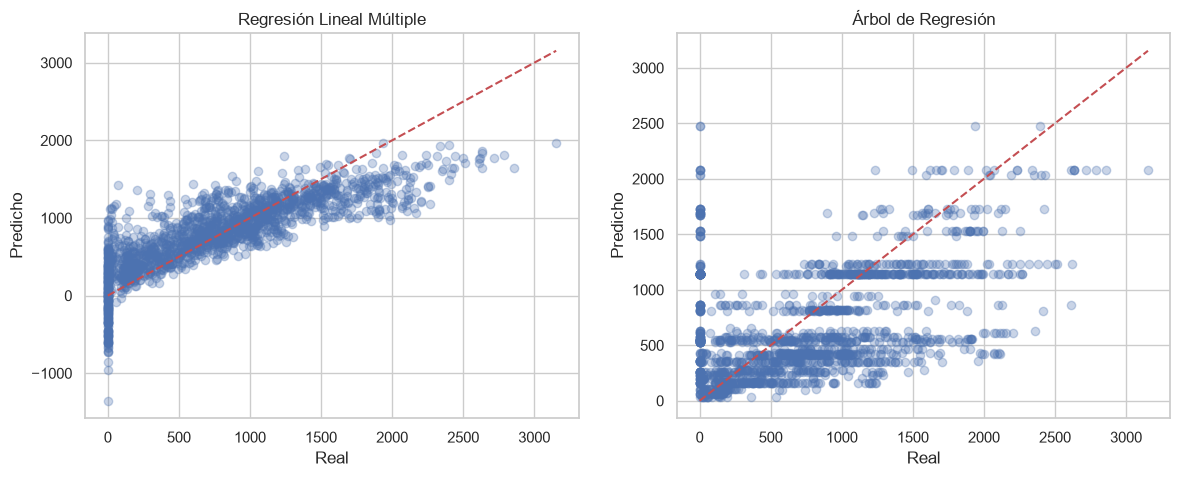

In [81]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (n, p) in zip(axes, [('Regresión Lineal Múltiple', pred_lr), ('Árbol de Regresión', pred_dtr)]):
    ax.scatter(y_testreg, p, alpha=0.3)
    ax.plot([0, y_testreg.max()], [0, y_testreg.max()], 'r--')
    ax.set(title=n, xlabel='Real', ylabel='Predicho')
plt.show()

<b>Gráfica Alternativa de las Últimas 2 Semanas para Comprender las Diferencias</b>

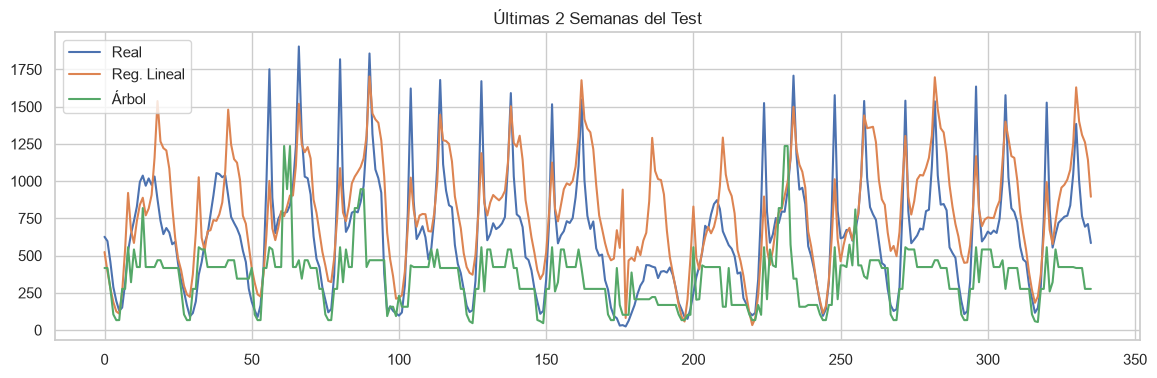

In [77]:
ult = 24 * 14
plt.figure(figsize=(14, 4))
plt.plot(y_testreg.values[-ult:], label='Real')
plt.plot(pred_lr[-ult:], label='Reg. Lineal')
plt.plot(pred_dtr[-ult:], label='Árbol')
plt.legend(); plt.title("Últimas 2 Semanas del Test")
plt.show()

<b>Interpretación de las Visualizaciones de Valores Reales y Predichos</b>
<p>
Las representaciones visuales de los resultados confirman de manera contundente las debilidades estructurales y las marcadas diferencias de rendimiento entre ambos algoritmos, respaldando así las métricas numéricas obtenidas. Al examinar tanto la dispersión de los errores como el comportamiento temporal de las predicciones, se hace evidente cómo la naturaleza matemática de cada modelo interactúa de forma deficiente con la partición cronológica de los datos.
    
En el caso de la Regresión Lineal Múltiple, el gráfico de dispersión muestra una correlación razonable, con los puntos agrupados en torno a la línea diagonal de ajuste perfecto. Asimismo, al observar la evolución temporal en las últimas dos semanas del test, se nota que el modelo logra capturar la frecuencia y la forma de los ciclos diarios de alquiler gracias a la estructuración categórica de las horas. Sin embargo, la rigidez de su ecuación provoca dos fallos críticos: genera un volumen significativo de predicciones por debajo de cero que son físicamente imposibles para el recuento de bicicletas, y subestima crónicamente la demanda máxima, formando una barrera horizontal de error cuando la realidad supera las 2000 unidades. Aunque el modelo oscila en sincronía con el ritmo del día, no logra replicar la amplitud o altura exacta de los picos. 

Por su parte, el Árbol de Regresión exhibe problemas severos que ilustran visualmente su deficiente coeficiente de determinación (R²). Su gráfico de dispersión revela un patrón fuertemente escalonado, un defecto que producen los árboles de decisión que asignan un mismo valor promedio estático a todas las observaciones que caen dentro de una hoja o nodo terminal. Esta limitación se agrava en la vista de las últimas 2 semanas, donde el modelo fracasa de forma estrepitosa al intentar replicar las subidas y bajadas diarias de los usuarios. En lugar de acompañar la tendencia, la predicción se mantiene plana o estancada en niveles muy bajos (alrededor de 250 a 500 bicicletas) durante días enteros, ignorando por completo los aumentos repentinos que rebasan las 1500 unidades. 

El diagnóstico gráfico expone que ninguno de los dos modelos base está listo para operar con precisión operativa en un entorno real. Mientras que la regresión lineal entiende la temporalidad cíclica pero rompe las reglas matemáticas del negocio arrojando cifras negativas, el árbol de regresión demuestra que sus ramificaciones aprendidas en el pasado pierden toda validez cuando se enfrenta a los cambios dinámicos del periodo de prueba.
</p>

<h3>2.8 Comparación de los Modelos y Selección</h3>

Al analizar los errores numéricos y el comportamiento gráfico, se determina que la Regresión Lineal Múltiple es el modelo que ofrece los mejores resultados para este problema. Este algoritmo logra explicar el 68.68 % de la variabilidad de la demanda (R² = 0.6868), superando por un margen abrumador al Árbol de Regresión, el cual apenas captura el 12.12 % de la varianza. La regresión lineal consigue adaptarse razonablemente a los ciclos diarios gracias a la dummificación de sus variables, mientras que el árbol fracasa de forma estrepitosa al intentar extrapolar reglas espaciales sobre una partición de datos cronológica. 

A pesar de ser el modelo ganador de la comparativa, la Regresión Lineal presenta errores estructurales que limitan su fiabilidad. Al aplicar una ecuación matemática continua, el algoritmo genera estimaciones con valores negativos en momentos de baja actividad, lo cual es lógicamente incorrecto para un recuento físico de unidades. Además, subestima sistemáticamente los grandes picos de alquiler, creando un límite predictivo que le impide advertir los volúmenes reales que ocurren en las horas de mayor tráfico comercial. 

Por su parte, la naturaleza de los errores del Árbol de Regresión lo descartan por completo como una opción viable. Al enfrentarse a las semanas del conjunto de prueba, el modelo colapsa y arroja predicciones estancadas en forma de bandas horizontales de bajo volumen. Este comportamiento demuestra que las reglas hiperespecíficas aprendidas durante los primeros meses del año no tienen la capacidad de adaptarse ni pronosticar las fluctuaciones dinámicas del futuro. 

Si el modelo de Regresión Lineal se implementara de forma automática en el sistema de logística de bicicletas de Seúl, la empresa enfrentaría severas consecuencias operativas. En primer lugar, los pronósticos negativos podrían generar excepciones informáticas o instrucciones erróneas en los sistemas de redistribución (por ejemplo, ordenar a un camión que asigne "-50 bicicletas" a una estación). En segundo lugar, al no anticipar correctamente la magnitud de los picos de demanda, el sistema sufriría desabastecimiento de bicicletas en las estaciones durante las horas de mayor rentabilidad.

Para que esta solución analítica sea segura y rentable en un entorno de producción, la organización requeriría aplicar barreras de seguridad inmediatas (como ignorar cualquier predicción negativa a cero) para evitar fallos. Además, el negocio padecerá la pérdida de clientes y de ingresos por estaciones vacías por malas planificaciones que no contemplaron apropiadamente picos inesperados.


<h3>2.9 Preguntas de Análisis</h3>

<b>¿Consideras que el modelo seleccionado proporciona predicciones suficientemente confiables para apoyar decisiones reales en la organización? Justifica tu respuesta utilizando las métricas obtenidas.</b>

Al analizar los errores numéricos y el comportamiento gráfico, se determina que la Regresión Lineal Múltiple es el modelo que ofrece los mejores resultados para este problema. Este algoritmo logra explicar el 68.68 % de la variabilidad de la demanda (R² = 0.6868), superando por un margen abrumador al Árbol de Regresión, el cual apenas captura el 12.12 % de la varianza. La regresión lineal consigue adaptarse razonablemente a los ciclos diarios gracias a la dummificación de sus variables, mientras que el árbol fracasa de forma estrepitosa al intentar extrapolar reglas espaciales sobre una partición de datos cronológica. 

A pesar de ser el modelo ganador de la comparativa, la Regresión Lineal presenta errores estructurales que limitan su fiabilidad. Al aplicar una ecuación matemática continua, el algoritmo genera estimaciones con valores negativos en momentos de baja actividad, lo cual es lógicamente incorrecto para un recuento físico de unidades. Además, subestima sistemáticamente los grandes picos de alquiler, creando un límite predictivo que le impide advertir los volúmenes reales que ocurren en las horas de mayor tráfico comercial. 

Aunque la Regresión Lineal Múltiple se posiciona como el mejor algoritmo dentro de esta evaluación al explicar el 68.68 % de la variabilidad de la demanda (R² = 0.6868), sus resultados no proporcionan la confiabilidad suficiente para operar de manera autónoma ni apoyar decisiones críticas en un entorno de negocio real. Este modelo sirve adecuadamente como un punto de partida analítico para comprender los ciclos diarios, pero sus limitaciones estructurales y su margen de error actual lo descartan como una herramienta definitiva para la logística automatizada de la organización. 
El principal impedimento para su implementación radica en su insostenible margen de error operativo. El modelo presenta un Error Absoluto Medio (MAE) de 256.8, lo que significa que se equivoca sistemáticamente por un volumen cercano a las 257 bicicletas por cada hora predicha. Este fallo representa un 33.92 % respecto a la demanda media total, una cifra que, llevada a la práctica comercial, provocaría el envío incesante de cientos de bicicletas sobrantes o faltantes a las diversas estaciones. Una reubicación de la flota basada en estos datos multiplicaría los gastos de transporte por fletes innecesarios e incrementaría fuertemente la insatisfacción de los usuarios. 

A este problema logístico se suma el alto riesgo de desabastecimiento en las franjas horarias más críticas. El modelo registra un RMSE de 343.2, un valor que es 1.34 veces mayor que el MAE, lo que confirma matemáticamente que el algoritmo comete sus equivocaciones más severas precisamente al intentar predecir los grandes picos de demanda máxima. Al no lograr anticipar estos escenarios y dejar más del 31 % de la variabilidad fuera de radar, el negocio se quedaría sin unidades disponibles justo en las horas de mayor tráfico, perdiendo oportunidades de ingresos seguras y dañando la reputación del servicio. 

Finalmente, la naturaleza de la ecuación lineal introduce inconsistencias lógicas que pondrían en peligro los sistemas de software de la compañía. Como se demostró en los gráficos de dispersión, el algoritmo genera estimaciones con valores negativos en momentos de baja actividad. Alimentar un sistema de gestión de inventarios con predicciones negativas requeriría validaciones manuales constantes o parches informáticos (como truncar forzosamente los resultados a cero) para evitar que el programa colapse. Para que la organización dependa de estos pronósticos de manera segura, será imperativo avanzar hacia modelos de ensamblaje más sofisticados e integrar variables de demanda histórica que corrijan estructuralmente estos fallos. 


<h2>3. Conclusiones respecto a la Interpretación desde la Inteligencia de Negocios</h2>